---
title: "Whitman's two-film theory, and what his three runs can actually test"
description: "The resistance-in-series picture that every absorption calculation still uses, rebuilt as the diffusion problem it claims to be, and then measured against the three runs Whitman published with it. His equilibrium curve is reconstructed from four equilibrium pairs in his own table rather than digitised from his figure; his worked example is reproduced end to end with his printed numbers held out; and the one prediction he holds out is 99.4 % gas-film controlled, so deleting the liquid film entirely moves it by 0.6 % and moves it closer to the measurement."
categories: [sec:A, struct:S3, tier:T0, data:tier3, phase:gas-liquid]
date: 2026-08-05
---

# Whitman's two-film theory, and what his three runs can actually test

**Catalog ID:** `A3.1` · **Structures:** `S3` (1D steady BVP) · **Tier:** T0

Two films in series, one equilibrium at the interface between them, and the
absorption rate is whatever both films can pass at once:

$$\frac{\mathrm{d}W}{\mathrm{d}\theta} \;=\; k_p\,(p_1-p_2)\;=\;k_c\,(c_2-c_3),
\qquad p_2 = f(c_2).$$

That is the whole of Whitman (1923). It is one of the most-cited results in
chemical engineering, and it is an *algebraic* statement, not a differential
one, which makes it easy to "validate" by rearranging it.

So this page does three separate things and keeps them apart.

1. **Reproduces Whitman's worked example**: the interface pair he had to find
   by hand on a chart, the liquid-film coefficient he derived from it, and the
   rate he predicted for a run he held out. All of it from Table 1's printed
   numbers, with **his equilibrium curve reconstructed rather than digitised**.
2. **Rebuilds the two films as a steady-diffusion problem in pymrm**, with the
   equilibrium jump at the interface as a coupling condition, and says plainly
   that its agreement with the algebra is an identity.
3. **Measures what his data can test.** Three runs, two coefficients. The one
   held-out prediction is 99.4 % controlled by the gas film, so **deleting the
   liquid film entirely** moves it by 0.6 %, and moves it *closer* to the
   observed rate. Sherwood and Pigford wrote in 1951 that the theory "has never
   been adequately checked experimentally". This page puts a number on why.

In [1]:
# Bootstrap: the pymrm this page was checked with, and the gallery files it was
# published with. Works in a checkout, in CI and on a fresh Colab VM.
GALLERY_REF = "gallery-2026.11.01.5"  # replaced by the release tag at publication
PYMRM = ">=3.3.0,<4"  # equals meta.yaml pymrm_min_version, up to the next major
PAGE = "A3.1-whitman-two-film"  # equals the page directory

import os, sys, urllib.request
from pathlib import Path
_shared = next((p / "shared" for p in (Path.cwd(), *Path.cwd().parents)
                if (p / "shared" / "gallery_bootstrap.py").is_file()), None)
if _shared is None:
    _shared = (Path(os.environ.get("XDG_CACHE_HOME") or Path.home() / ".cache")
               / "pymrm-gallery" / GALLERY_REF)
    _shared.mkdir(parents=True, exist_ok=True)
    urllib.request.urlretrieve(
        "https://raw.githubusercontent.com/computational-chemical-engineering/"
        f"pymrm-gallery/{GALLERY_REF}/shared/gallery_bootstrap.py",
        _shared / "gallery_bootstrap.py")
sys.path.insert(0, str(_shared))
sys.modules.pop("gallery_bootstrap", None)
from gallery_bootstrap import setup
setup(PAGE, PYMRM, GALLERY_REF);  # the semicolon stops the cell echoing the path

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from scipy.optimize import brentq, least_squares
from gallery_utils import load_data, load_meta, cite_data, Claims
from model import (Equilibrium, TwoFilm, two_film_algebraic,  # this page's model.py
                   no_liquid_film_rate, reacting_film_rate)

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.width", 200, "display.max_columns", 20)
claims = Claims(PAGE.split("-")[0])
BREAK = []


def brk(row, metric, broken):
    """One injected defect: ``broken`` is what claim ``metric`` becomes with it."""
    caught = claims.breaks(row, metric, broken)
    BREAK.append((row, metric, claims[metric], float(broken), caught))
    return caught

## Background

By 1923 everyone agreed the absorption rate had the form

$$\frac{\mathrm{d}W}{\mathrm{d}\theta} = \text{coefficient} \times \text{driving potential},
\tag{1}$$

and nobody agreed on the potential. One camp (Lewis 1916; Whitman & Keats 1922)
wrote it as a **pressure** difference, the other (Donnan & Masson 1920; Van
Arsdel 1920) as a **concentration** difference:

$$\text{Driving potential} = p_g-p_l = p, \tag{2}$$

$$\text{Driving potential} = c_g-c_l = c, \tag{3}$$

with, in his words, $p_l$ = "the partial pressure of solute exerted by the
liquid" and $c_g$ = "the concentration of liquid which would be in equilibrium
with the gas" (reprint page 430). **Those two definitions are the whole basis of
this page's equilibrium reconstruction**, so they are quoted here rather than
paraphrased. Two pages later Whitman writes the same two potentials in the
station subscripts of his Fig. 1, as $(p_1 - p_3)$ and $(c_1 - c_3)$ in his
eqs. (5) and (6), so $p_l = p_3$ and $c_g = c_1$. The rest of this page uses
the numbered subscripts throughout; the substitution is his, and it is flagged
here because it is the one place where a subscript convention carries an
extraction claim.

Whitman's point is that this is a false choice. Both potentials are real and
they act **in series**, on either side of an interface where the two phases are
in equilibrium. Quoting the paper (reprint page 430):

> Conditions at the outside of the gas film (1) are the same as in the main body
> of gas, while those at the inside of the liquid film (3) are the same as in
> the main body of liquid. The gas and liquid at the boundary between the two
> films (2) are in equilibrium. Absorption occurs therefore through two films in
> series.

The two formulations coincide only when $p = kc$; otherwise, he writes, "the
overall coefficients $K_c$ or $K_p$ would have no significance."

**Where the equations on this page come from.** The 1923 original in *Chemical
and Metallurgical Engineering* is pre-DOI and unreachable. It is **reprinted
verbatim** as item 5 of the series *"Pioneer papers in convective mass
transfer"* in *Int. J. Heat Mass Transfer* **5** (1962) 429–433, which carries
its own DOI and is on disk. The reprint's header states its origin: *"W. G.
WHITMAN: The two-film theory of gas absorption, Chemical and Metallurgical
Engineering 29, 146–148 (1923). Reprinted with permission from Chemical
Engineering, Copyright 1923, McGraw-Hill Publishing Co."*

Every equation, every table cell and every constant used here was read off a
**300 ppi render of the 1962 printing, which is that scan's native resolution**
(`pdfimages -list` reports CCITT-G4 bilevel images at 300 ppi, so rendering
larger only interpolates). Each numeric was then **cropped and re-read at that
resolution**, not read at page scale, because the 1962 typesetting sets the
decimal point as a mid-dot (`41·0`, `0·067`), which survives digit-scale
inspection and nothing else. The PDF's text layer is an OCR of the same scan and
is unusable for numbers: it returns eq. (7) as `2,$~=PL~~2Lz` and run 3's $K_c$
as `om7`.

**All page references on this page are to the 1962 reprint, 429–433.** The 1923
range 146–148 appears only in that header line; it is inherited, not verified,
and no individual 1923 page is cited here. The header prints **no issue
number**, so none is given anywhere on this page.

**The Editor's Foreword is not Whitman.** The reprint opens with a 1962
foreword signed "D.B.S." which quotes Sherwood and Pigford's 1951 preface to
*Absorption and Extraction*:

> Methods of applying the Whitman "two-film" theory to various design problems
> have been extended and refined, but it is curious that after 28 years the
> theory itself has never been adequately checked experimentally.

That sentence is editorial commentary about Whitman, not a claim of his, and
this page never attributes it to him. It is quoted because it is the question
this page can answer quantitatively. The Foreword also notes, correctly, that
Whitman knew the film was a fiction: *"the gas and liquid films at the boundary
can be indicated as having a definite thickness, although actually no such sharp
demarcation exists"* is Whitman's own sentence, on reprint page 430.

**The competing pictures are other pages, and the three-way comparison lives on
one of them.** Higbie's penetration theory (`A3.2`) and Danckwerts' surface
renewal (`A3.3`) replace the steady film with an unsteady one and predict a
different exponent on the diffusivity. Whitman's three runs cannot see that
exponent, so the comparison is not made here; it is made on
[`A3.2`](../A3.2-higbie-penetration/), the only one of the three pages holding
all three sources in hand.

## The published model

Whitman's subscripts are positions in his Fig. 1: **1** the outside of the gas
film (the bulk gas), **2** the interface, **3** the inside of the liquid film
(the bulk liquid). The equations that matter, transcribed from reprint pages
431 and 432:

$$\frac{\mathrm{d}W}{\mathrm{d}\theta} \;=\; k_p\,(p_1 - p_2)\;=\;k_c\,(c_2 - c_3)
\tag{4}$$

with $k_p$ "the coefficient of diffusion through the gas film" and $k_c$ that
through the liquid film. The two overall coefficients previously proposed are

$$\frac{\mathrm{d}W}{\mathrm{d}\theta} = K_p\,(p_1-p_3),\tag{5}$$

$$\frac{\mathrm{d}W}{\mathrm{d}\theta} = K_c\,(c_1-c_3).\tag{6}$$

Dividing eq. (4) by itself and by eq. (5) gives the two working forms:

$$\frac{k_c}{k_p} = \frac{p_1-p_2}{c_2-c_3},\tag{7}$$

$$\frac{K_p}{k_p} = \frac{p_1-p_2}{p_1-p_3}.\tag{8}$$

**The system closes only with the equilibrium relation.** Eq. (4) is two
equations in three unknowns ($\mathrm{d}W/\mathrm{d}\theta$, $p_2$, $c_2$); what
closes it is $p_2 = f(c_2)$, the equilibrium curve, which Whitman supplies as
Figs 2 and 3. For hydrogen chloride over aqueous HCl at 30 °C that curve is
strongly non-linear, which is the point of the paper, because it is exactly
where eqs. (5) and (6) stop meaning anything.

**Read carefully, eqs. (4) to (8) are two different kinds of statement.**
Eqs. (5) to (8) are *definitions and rearrangements*: given $p_2$, the split
$1/K_p = 1/k_p + (p_2-p_3)/(\mathrm{d}W/\mathrm{d}\theta)$ is arithmetic and
cannot be wrong. The **model** is the pair of assertions that $k_p$ and $k_c$
are constants of the apparatus and that the interface is at equilibrium. Those
are what can fail, and this page keeps the two apart everywhere.

## Parameters and assumptions

Whitman reports no apparatus dimensions, no interfacial area, no flow rates and
no run duration. So:

- $k_p$, $k_c$, $K_p$, $K_c$ are **per-apparatus conductances**, in
  g h⁻¹ mmHg⁻¹ and g h⁻¹ (g/l)⁻¹. They are not per-unit-area film coefficients
  and no film thickness or diffusivity can be recovered from them. The pymrm
  model below therefore uses films of unit thickness so that the conductance
  $D/\delta$ *is* the printed coefficient; the thickness is a gauge choice and
  nothing on this page depends on it. Reconstructing a $\delta$ would be
  fabrication.
- All three runs are at 30 °C, gas and liquid.
- $k_p$ and $k_c$ are assumed the same in all three runs. Whitman states the
  opposite in general ("the values of $k_p$ and $k_c$ will, of course, be
  dependent on experimental conditions") and then assumes constancy for the
  worked example. Nothing in three runs can check it, and this page does not.
- The interface is at equilibrium, and the equilibrium relation is the one
  plotted in Figs 2 and 3.

**The equilibrium curve is reconstructed, not digitised.** Digitising Fig. 3
would be the obvious move and it is unnecessary. Whitman's subscript convention
makes $(c_1, p_1)$ and $(c_3, p_3)$ *equilibrium pairs*: $c_1$ is "the
concentration of liquid which would be in equilibrium with the gas" at $p_1$,
and $p_3$ is "the partial pressure of solute exerted by the liquid" at $c_3$.
Table 1 therefore prints **four distinct equilibrium points**. Fig. 3 plots a
straight dashed line on $\log_{10} p$ against $c$ axes; fitting that form to the
four printed points gives the curve, with every input traceable to a printed
number and no pixel measured anywhere. Run 3's $(c_3, p_3)$ is not usable: its
printed $p_3$ is a zero, a rounding.

**Table 1 corroborates that reading on its own**, before any fit: runs 2 and 3
share $p_1$, and the table prints the same $c_1$ for **both**, while their bulk
concentrations, their $K_c$ values and their rates all differ. That is what an
equilibrium concentration must do and what a bulk or inlet concentration has no
reason to do. It is shown below.

The four points are over-determined by two, so the fit **has residuals and can
fail**: a single mis-read digit anywhere in those eight table cells would show
up at once. That is the page's transcription check.

## The data

Two CSVs, both transcriptions of printed characters read off renders of the 1962
reprint at its native 300 ppi, with every numeric cropped and re-read at that
resolution. Neither is digitised and neither contains a pixel measurement.

- `whitman-1923-table1.csv`: the ten printed columns of Table 1 (reprint
  page 431): three runs, each with the observed rate, the two pressures, the two
  concentrations, the two differences and the two overall coefficients.
- `whitman-1923-printed-results.csv`: everything Whitman prints outside
  Table 1 (reprint pages 431–432): the numbers of his worked example, three
  ratios he states in words, his "negligible up to approximately 250 g/l", the
  30 °C, and the four printed **axis tick labels** of Fig. 3. The tick labels are
  characters, not positions; no curve or marker is extracted.

**Tier.** Table 1 is a measurement, so it is tier 3, but a very small one:
three runs, no replicates, no error estimate, no apparatus description, and the
paper's own subtitle is *"A Preliminary Experimental Confirmation"*. Whitman
writes that the data "are insufficient to prove definitely the truth of the
two-film theory". Everything derived from the worked example is tier 6, being
the author's own arithmetic and his own graphical readings.

**What is held out.** The reconstruction below uses only Table 1. Whitman's
worked-example numbers ($p_2$ and $c_2$ of run 1, $k_c$, the run-2 interface
pair, and the predicted run-2 rate) are **never inputs**. They are targets.

This page loads no other page's dataset.

In [3]:
t1 = load_data("whitman-1923-table1.csv", page=PAGE)
pr = load_data("whitman-1923-printed-results.csv", page=PAGE).set_index("quantity")
print(cite_data(load_meta("whitman-1923-table1.csv", page=PAGE)))
display(t1)


def printed(q):
    """A number Whitman printed, by name. Nothing in this notebook types one."""
    return float(pr.loc[q, "value"])


RUNS = t1.to_dict("records")
R = {int(r["run"]): r for r in RUNS}                    # Table 1 by run number
OBS = {k: float(r["dW_dtheta_g_per_h"]) for k, r in R.items()}
P1 = {k: float(r["p1_mmHg"]) for k, r in R.items()}
C3 = {k: float(r["c3_g_per_l"]) for k, r in R.items()}
RATE_HALF_UNIT = 0.05        # g/h: half a unit in the last printed place of the rate column

Whitman, W. G. (1923) — Chemical and Metallurgical Engineering 29, 146-148 — table


,run,dW_dtheta_g_per_h,p1_mmHg,p3_mmHg,delta_p_mmHg,c1_g_per_l,c3_g_per_l,delta_c_g_per_l,K_p,K_c
0,1,41.0,225,55.0,170.0,425,378,47,0.24,0.870
1,2,24.0,41,0.3,40.7,368,204,164,0.59,0.146
2,3,24.1,41,0.0,41.0,368,9,359,0.59,0.067


### Table 1 is internally consistent, and that check has no power

The two difference columns and the two coefficient columns are recomputed from
the printed rate and the printed pressures and concentrations. This is a
**transcription check only**: $K_p$ and $K_c$ are *defined* as the rate over the
difference, so agreement here is arithmetic, not physics. It is kept because it
is the cheapest way to catch a dropped mid-dot decimal separator: the 1962
typesetting writes 41.0 as `41·0`, and the PDF's own text layer loses it.

In [4]:
def table1_consistency(t):
    """Worst deviation of the difference columns, and of the coefficient columns (%)."""
    dp = t.p1_mmHg - t.p3_mmHg - t.delta_p_mmHg
    dc = t.c1_g_per_l - t.c3_g_per_l - t.delta_c_g_per_l
    kp = 100 * (t.dW_dtheta_g_per_h / t.delta_p_mmHg / t.K_p - 1)
    kc = 100 * (t.dW_dtheta_g_per_h / t.delta_c_g_per_l / t.K_c - 1)
    return (float(np.abs(np.r_[dp, dc]).max()), float(np.abs(np.r_[kp, kc]).max()),
            pd.DataFrame(dict(run=t.run, dp_dev=dp, dc_dev=dc, Kp_reldev_pct=kp,
                              Kc_reldev_pct=kc)))


TABLE1_DIFF_MAX, TABLE1_COEF_MAX, chk = table1_consistency(t1)
display(chk.round(4))
print(f"difference columns close exactly: worst deviation below 1e-9 (here {TABLE1_DIFF_MAX:.1e})")
print(f"coefficient columns, worst relative deviation: {TABLE1_COEF_MAX:.3f} % "
      "(the printed rounding of K_p and K_c)")
claims.bound("table1_diff_columns_max_dev", TABLE1_DIFF_MAX, max=1e-9, basis="identity",
             note="the printed differences are the subtraction of the printed columns")
claims.value("table1_coef_columns_max_pct", TABLE1_COEF_MAX, rtol=0.01)

,run,dp_dev,dc_dev,Kp_reldev_pct,Kc_reldev_pct
0,1,0.0,0,0.4902,0.2690
1,2,0.0,0,-0.0541,0.2339
2,3,0.0,0,-0.3721,0.1954


difference columns close exactly: worst deviation below 1e-9 (here 0.0e+00)
coefficient columns, worst relative deviation: 0.490 % (the printed rounding of K_p and K_c)


### Whitman's three stated ratios, recomputed

Three claims are made in words on reprint page 432. Two are right; the third is
loose.

In [5]:
def stated_ratios(t):
    """The three ratios of reprint page 432 from the printed coefficient columns."""
    K = {int(r["run"]): (r["K_p"], r["K_c"]) for _, r in t.iterrows()}
    return (K[2][0] / K[1][0], K[1][1] / K[3][1], K[2][1] / K[3][1])


RATIOS = stated_ratios(t1)
for name, got, q, quote in zip(
        ("K_p(run 2)/K_p(run 1)", "K_c(run 1)/K_c(run 3)", "K_c(run 2)/K_c(run 3)"), RATIOS,
        ("ratio_Kp_run2_over_run1", "ratio_Kc_run1_over_run3", "ratio_Kc_run2_over_run3"),
        ("'increases nearly two and one-half fold'",
         "'the first run being twelvefold that for run 3'",
         "'differ more than twofold', a lower bound, satisfied")):
    print(f"  {name} = {got:6.3f}   Whitman states {printed(q):<5g}  {quote}")
print(f"\n  The 'twelvefold' is the loose one: the printed columns give "
      f"{RATIOS[1]:.2f}, thirteen, not twelve.")
claims.value("prose_Kp_ratio_recomputed", RATIOS[0], rtol=1e-3)
claims.value("prose_twelvefold_recomputed", RATIOS[1], rtol=1e-3)
claims.value("prose_twofold_recomputed", RATIOS[2], rtol=1e-3)

  K_p(run 2)/K_p(run 1) =  2.458   Whitman states 2.5    'increases nearly two and one-half fold'
  K_c(run 1)/K_c(run 3) = 12.985   Whitman states 12     'the first run being twelvefold that for run 3'
  K_c(run 2)/K_c(run 3) =  2.179   Whitman states 2      'differ more than twofold', a lower bound, satisfied

  The 'twelvefold' is the loose one: the printed columns give 12.99, thirteen, not twelve.


### First, the evidence that the printed c1 really is an equilibrium concentration

The reading above is Whitman's own definition, but Table 1 also *tests* it, with
no fit and no figure. If $c_1$ is "the concentration of liquid which would be in
equilibrium with the gas", it is a function of $p_1$ **and of nothing else**,
so two runs at the same $p_1$ must print the same $c_1$, however much else
differs between them. Runs 2 and 3 are exactly that pair.

In [6]:
def c1_values_at_shared_p1(t):
    """Distinct printed c1 among the runs whose p1 is shared with another run."""
    dup = t[t.duplicated("p1_mmHg", keep=False)]
    return dup, sorted(set(dup["c1_g_per_l"]))


shared, C1_SHARED = c1_values_at_shared_p1(t1)
display(shared[["run", "p1_mmHg", "c1_g_per_l", "c3_g_per_l", "dW_dtheta_g_per_h", "K_c"]])
print(f"runs {list(shared.run)} share p1 = {shared.p1_mmHg.iloc[0]:g} mmHg and print "
      f"c1 = {C1_SHARED} g/l: {len(C1_SHARED)} value, printed twice.")
print(f"Everything else about them differs: c3 = {list(shared.c3_g_per_l)} g/l, "
      f"K_c = {list(shared.K_c)}, rate = {list(shared.dW_dtheta_g_per_h)} g/h.")
print("A bulk, inlet or mean liquid concentration would have no reason to coincide;")
print("an equilibrium concentration read off one pressure has no choice.")
claims.exact("c1_distinct_at_shared_p1", len(C1_SHARED))

,run,p1_mmHg,c1_g_per_l,c3_g_per_l,dW_dtheta_g_per_h,K_c
1,2,41,368,204,24.0,0.146
2,3,41,368,9,24.1,0.067


runs [2, 3] share p1 = 41 mmHg and print c1 = [368] g/l: 1 value, printed twice.
Everything else about them differs: c3 = [204, 9] g/l, K_c = [0.146, 0.067], rate = [24.0, 24.1] g/h.
A bulk, inlet or mean liquid concentration would have no reason to coincide;
an equilibrium concentration read off one pressure has no choice.


### Reconstructing the equilibrium curve from Table 1

Four printed equilibrium pairs, one two-parameter form, two degrees of freedom
left over. The residuals below are what the page's transcription rests on.

In [7]:
def equilibrium_pairs(t):
    """(c1, p1) and (c3, p3) of every run, by Whitman's definitions (reprint page 430).

    Duplicates are dropped, and so is a pair whose printed pressure is 0 (run 3's
    p3, a rounding)."""
    pairs = np.array([[r["c1_g_per_l"], r["p1_mmHg"]] for _, r in t.iterrows()]
                     + [[r["c3_g_per_l"], r["p3_mmHg"]] for _, r in t.iterrows()], float)
    pairs = np.unique(pairs, axis=0)
    return pairs[pairs[:, 1] > 0]


EQ_PAIRS = equilibrium_pairs(t1)
C_EQ, P_EQ = EQ_PAIRS[:, 0], EQ_PAIRS[:, 1]
EQ = Equilibrium.fit(C_EQ, P_EQ)
EQ_RESID_MAX_PCT, EQ_RESID_MAX_GL = EQ.residuals(C_EQ, P_EQ)
DECADES = float(np.log10(P_EQ.max() / P_EQ.min()))
print(f"log10(p/mmHg) = {EQ.A:.6f} + {EQ.B:.6f} (c / (g/l))")
for c_, p_ in EQ_PAIRS:
    r_ = np.log10(p_) - (EQ.A + EQ.B * c_)
    print(f"   c = {c_:6.1f} g/l   p = {p_:8.3f} mmHg    residual "
          f"{100 * (10 ** r_ - 1):+7.3f} % in p   {r_ / EQ.B:+6.3f} g/l in c")
print(f"\n  {len(EQ_PAIRS)} points, 2 parameters, {len(EQ_PAIRS) - 2} degrees of freedom")
print(f"  worst residual {EQ_RESID_MAX_PCT:.3f} % in p  ({EQ_RESID_MAX_GL:.3f} g/l in c) "
      f"over {DECADES:.2f} decades of pressure")
claims.value("eq_curve_worst_resid_pct", EQ_RESID_MAX_PCT, rtol=0.01)
claims.value("eq_curve_worst_resid_gl", EQ_RESID_MAX_GL, rtol=0.01)
claims.value("eq_pairs_decades", DECADES, rtol=1e-3)

log10(p/mmHg) = -3.176820 + 0.013011 (c / (g/l))
   c =  204.0 g/l   p =    0.300 mmHg    residual  -0.056 % in p   -0.019 g/l in c
   c =  368.0 g/l   p =   41.000 mmHg    residual  +0.383 % in p   +0.128 g/l in c
   c =  378.0 g/l   p =   55.000 mmHg    residual  -0.199 % in p   -0.067 g/l in c
   c =  425.0 g/l   p =  225.000 mmHg    residual  -0.127 % in p   -0.042 g/l in c

  4 points, 2 parameters, 2 degrees of freedom
  worst residual 0.383 % in p  (0.128 g/l in c) over 2.88 decades of pressure


**One corroboration from Fig. 3's printed axis box, and one from his prose.**

Fig. 3's printed ticks bound a box, and the dashed line drawn in it **exits at
the top-right corner**, visible at a glance, no measurement involved.
Extrapolating the reconstruction to the printed abscissa ticks should therefore
reproduce the printed *top* ordinate tick.

**It cannot do the same at the bottom, and the arithmetic says why before the
number is looked at.** A straight line of the reconstructed slope spans
$B$ times the abscissa width in log units, which is *less* than the box is
tall. A line that leaves through the top-right corner must therefore start
somewhere **above** the bottom-left one, by exactly the difference, so the
bottom tick is not a target and a deviation there is not a failure. Both ends
are printed below; only the top one is a check, and the page counts it as one
corroboration, not two.

The second corroboration is Whitman's own sentence that the back pressure is
"negligible up to concentrations of approximately 250 g/l": the reconstruction
should make it small there.

In [8]:
C_LO, C_HI = printed("fig3_abscissa_min"), printed("fig3_abscissa_max")
O_LO, O_HI = printed("fig3_ordinate_min"), printed("fig3_ordinate_max")


def axis_box(eq):
    """Top-corner deviation, and the signed identity bottom = shortfall + top."""
    lo, hi = eq.A + eq.B * C_LO, eq.A + eq.B * C_HI
    shortfall = (O_HI - O_LO) - eq.B * (C_HI - C_LO)
    return lo, hi, abs(hi - O_HI), (lo - O_LO) - (shortfall + (hi - O_HI)), shortfall


LO, HI, AXIS_TOP_DEV, AXIS_IDENTITY, SHORTFALL = axis_box(EQ)
print("Fig. 3's printed axis box, against the reconstruction extrapolated to it:")
print(f"   at c = {C_HI:.0f} g/l  reconstruction gives log10 p = {HI:+.3f}   "
      f"printed TOP tick    {O_HI:+.1f}   <-- the check")
print(f"   at c = {C_LO:.0f} g/l  reconstruction gives log10 p = {LO:+.3f}   "
      f"printed bottom tick {O_LO:+.1f}   <-- not a target")
print(f"\n   top-corner deviation    {AXIS_TOP_DEV:.4f} log10 units")
print(f"   bottom-corner deviation {LO - O_LO:.4f} log10 units, and expected:")
print(f"      printed box height                 {O_HI - O_LO:.3f} log units")
print(f"      line span over {C_LO:.0f} to {C_HI:.0f} g/l      "
      f"{EQ.B * (C_HI - C_LO):.3f} log units")
print(f"      shortfall + top deviation          {SHORTFALL + HI - O_HI:.4f}")
print(f"   bottom deviation minus (shortfall + top deviation): below 1e-12 "
      f"(here {abs(AXIS_IDENTITY):.1e}), an identity")
print("   A line of this slope cannot touch both corners of this box. It touches the")
print("   top one, which is where Whitman drew it.")
print("   (printed tick labels only: no pixel of either figure is measured)")
claims.value("fig3_axis_top_dev_log10", AXIS_TOP_DEV, rtol=0.01)
claims.bound("fig3_axis_bottom_identity", abs(AXIS_IDENTITY), max=1e-12, basis="identity",
             structural=True, note="bottom deviation = box shortfall + top deviation")

C_NEG = printed("c_negligible_backpressure")
P_NEG = float(EQ.p(C_NEG))
print(f"\nWhitman's 'negligible up to approximately {C_NEG:.0f} g/l':")
print(f"   reconstructed back pressure there = {P_NEG:.2f} mmHg, "
      f"{100 * P_NEG / P1[2]:.1f} % of run 2's driving pressure, "
      f"{100 * P_NEG / P1[1]:.1f} % of run 1's")
claims.value("negligible_backpressure_mmHg", P_NEG, rtol=0.01)

Fig. 3's printed axis box, against the reconstruction extrapolated to it:
   at c = 460 g/l  reconstruction gives log10 p = +2.808   printed TOP tick    +2.8   <-- the check
   at c = 180 g/l  reconstruction gives log10 p = -0.835   printed bottom tick -1.0   <-- not a target

   top-corner deviation    0.0081 log10 units
   bottom-corner deviation 0.1651 log10 units, and expected:
      printed box height                 3.800 log units
      line span over 180 to 460 g/l      3.643 log units
      shortfall + top deviation          0.1651
   bottom deviation minus (shortfall + top deviation): below 1e-12 (here 0.0e+00), an identity
   A line of this slope cannot touch both corners of this box. It touches the
   top one, which is where Whitman drew it.
   (printed tick labels only: no pixel of either figure is measured)

Whitman's 'negligible up to approximately 250 g/l':
   reconstructed back pressure there = 1.19 mmHg, 2.9 % of run 2's driving pressure, 0.5 % of run 1's


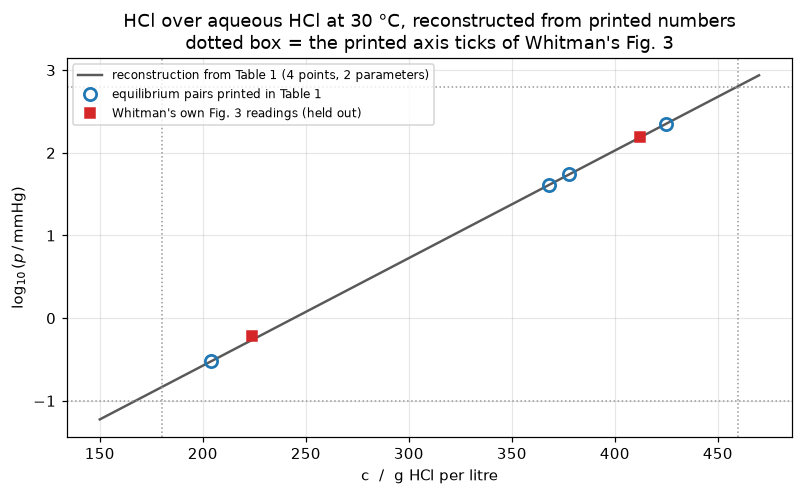

In [9]:
fig, ax = plt.subplots(figsize=(7.4, 4.6))
cc = np.linspace(150, 470, 400)
ax.plot(cc, np.log10(EQ.p(cc)), "-", lw=1.6, color="0.35",
        label="reconstruction from Table 1 (4 points, 2 parameters)")
ax.plot(C_EQ, np.log10(P_EQ), "o", ms=8, mfc="none", mew=1.8, color="C0",
        label="equilibrium pairs printed in Table 1")
ax.plot([printed("c2_run1"), printed("c2_run2")],
        np.log10([printed("p2_run1"), printed("p2_run2")]), "s", ms=7, color="C3",
        label="Whitman's own Fig. 3 readings (held out)")
for v in (O_LO, O_HI):
    ax.axhline(v, ls=":", lw=1, color="0.6")
for v in (C_LO, C_HI):
    ax.axvline(v, ls=":", lw=1, color="0.6")
ax.set_xlabel("c  /  g HCl per litre")
ax.set_ylabel(r"$\log_{10}(p\,/\,\mathrm{mmHg})$")
ax.set_title("HCl over aqueous HCl at 30 °C, reconstructed from printed numbers\n"
             "dotted box = the printed axis ticks of Whitman's Fig. 3")
ax.legend(fontsize=8, loc="upper left")
fig.tight_layout()
plt.show()

## PyMRM implementation

Whitman's "films" are stagnant layers in which the solute moves by diffusion
alone, so the pymrm rendering is not the algebra but the **two-domain steady
diffusion problem** the algebra summarises:

$$\frac{\mathrm{d}}{\mathrm{d}x}\!\left(-k_p \frac{\mathrm{d}p}{\mathrm{d}x}\right) = 0
\quad\text{on the gas film},\qquad
\frac{\mathrm{d}}{\mathrm{d}x}\!\left(-k_c \frac{\mathrm{d}c}{\mathrm{d}x}\right) + k_a\,c = 0
\quad\text{on the liquid film},$$

with $p = p_1$ at the outside of the gas film, $c = c_3$ at the inside of the
liquid film, and at the interface the two conditions that make it a *two-film*
problem: **flux continuity** and **local equilibrium** $p_2 = f(c_2)$. The
rate constant $k_a$ is zero for Whitman; it is used only in section 8.

`TwoFilm` in `model.py` lays the state out with `pymrm.BlockLayout` along the
one axis that runs through both films: the gas film `"p"` $(n, 1)$, the two
interface values `"p2"` and `"c2"` $(1, 1)$, the liquid film `"c"` $(n, 1)$.
Every block of the Jacobian is placed by name (`layout.place`), the bulk values
enter through `layout.put`, and the interface face of each film is a named
subdomain of its faces (its one slice is written once, in `_build_operators`),
selected with `pick`, so no offset into the state is typed by hand.
The two interface values are **external unknowns through `shapes_d`**: the
boundary value changes every Newton step, so it multiplies a *constant*
boundary matrix and the operators are assembled once. `construct_div` uses
`nu=0`, a plane film. Both boundary dictionaries are Dirichlet on the outward
normal ($a=0$, $b=1$: $b\,\phi = d$, so $\phi = d$ at that end), the physical
equation written beside them in `model.py`.

The system is linear except for $f$ in the single equilibrium row, so its
derivative is placed analytically and the Jacobian is exact. Newton starts
from the deleted-liquid-film state ($c_2 = c_3$), not from the algebraic
answer, with `scale=` giving every block its physical magnitude, because
`newton`'s step test is absolute and the unknowns are in mmHg and g/l. Each
solve is judged by its componentwise backward error
(`pymrm.checks.residual_check`), and the absorption rate is the gas-film flux
at the interface face, read with `compute_boundary_values`.

**Film thickness is a gauge.** Both films are given unit thickness so that the
conductance $D/\delta$ equals Whitman's printed coefficient. He publishes no
area, no thickness and no diffusivity, so nothing else is recoverable and
nothing on this page depends on the choice.

### The pymrm solve against the algebra: an identity, and labelled as one

A film with constant $D$, Dirichlet ends and no source has a **linear**
profile, and a conservative finite-volume discretisation reproduces it exactly
on any grid (the one-sided boundary gradient is exact for a linear profile).
So the agreement between `TwoFilm.solve` and `two_film_algebraic` below is
**algebraically guaranteed**: it confirms the operator assembly, the
`shapes_d` plumbing, the flux-continuity row and the equilibrium row, and
nothing else. It is blind to the grid, and it is *not* blind to a wrong
geometry index or a missing equilibrium jump; the break table shows both.

In [10]:
KP_R3 = float(R[3]["K_p"])                 # Whitman's k_p, the printed K_p of run 3
KC_W = printed("k_c_run1")                 # Whitman's printed k_c, a target only


def worked_kc(eq, kp=KP_R3, runs=R):
    """Whitman's steps 2 to 4: p2 of run 1 from eq. (4), c2 off the curve, then k_c."""
    p2 = runs[1]["p1_mmHg"] - runs[1]["dW_dtheta_g_per_h"] / kp
    c2 = float(eq.c(p2))
    return p2, c2, runs[1]["dW_dtheta_g_per_h"] / (c2 - runs[1]["c3_g_per_l"])


P2_1, C2_1, KC_1 = worked_kc(EQ)
SOLVES = {}
rows = []
for run in (1, 2, 3):
    tf = TwoFilm(KP_R3, KC_1, EQ.p, EQ.dpdc, n=40)
    s, a = tf.solve(P1[run], C3[run]), tf.algebraic(P1[run], C3[run])
    SOLVES[run] = s
    rows.append(dict(run=run, N_pymrm=s["N"], N_algebraic=a["N"],
                     reldev=abs(s["N"] / a["N"] - 1), p2=s["p2"], c2=s["c2"],
                     newton_it=s["nit"], backward_error=s["backward_error"],
                     flux_gap=abs(s["N_liquid_face"] / s["N_gas_face"] - 1)))
port = pd.DataFrame(rows)
display(port[["run", "N_pymrm", "N_algebraic", "p2", "c2", "newton_it"]])
PYMRM_VS_ALG = float(port.reldev.max())
NEWTON_BE_MAX = float(port.backward_error.max())
NEWTON_IT_MAX = int(port.newton_it.max())
FLUX_GAP = float(port.flux_gap.max())
print(f"n = 40 cells per film, k_p = {KP_R3}, k_c = {KC_1:.4f} (Whitman's, derived below)")
print(f"pymrm against the algebra, worst relative deviation: below 1e-11 "
      f"(here {PYMRM_VS_ALG:.1e}), an identity (port check)")
print(f"Newton from the deleted-liquid-film state: at most {NEWTON_IT_MAX} iterations, "
      f"backward error below 1e-12 (here {NEWTON_BE_MAX:.1e})")
print(f"gas and liquid face fluxes at the interface (compute_boundary_values) agree "
      f"below 1e-10 (here {FLUX_GAP:.1e})")
claims.bound("pymrm_vs_algebra_reldev", PYMRM_VS_ALG, max=1e-11, basis="identity",
             note="a linear profile is exact in the finite-volume scheme")
claims.bound("newton_worst_backward_error", NEWTON_BE_MAX, max=1e-12, basis="tolerance",
             note="pymrm.checks.residual_check at the returned state, newton tol 1e-12 scaled")
claims.bound("newton_max_iterations", NEWTON_IT_MAX, max=10, basis="chosen",
             note="exact Jacobian, quadratic convergence from the deleted-liquid-film state")
claims.bound("interface_flux_continuity", FLUX_GAP, max=1e-10, basis="identity",
             note="the flux-continuity row is this equation")


def grid_spread(nu=0):
    """Rate of run 1 on 3, 5, 40 and 600 cells, and its relative spread."""
    out = [(n, TwoFilm(KP_R3, KC_1, EQ.p, EQ.dpdc, n=n, nu=nu).solve(P1[1], C3[1])["N"])
           for n in (3, 5, 40, 600)]
    vals = [v for _, v in out]
    return out, (max(vals) - min(vals)) / abs(np.mean(vals))


GRID, GRID_SPREAD = grid_spread()
print("\ngrid independence, exact on any grid because the profile is linear:")
for n, N in GRID:
    print(f"   n = {n:4d}   N = {N:.9f} g/h")
print(f"   relative spread over n = 3 to 600: below 1e-9 (here {GRID_SPREAD:.1e}), "
      "round-off that grows with the conditioning of the finer grid")
claims.bound("grid_spread_rel_n3_to_n600", GRID_SPREAD, max=1e-9, basis="identity",
             note="no discretisation error; round-off only")

,run,N_pymrm,N_algebraic,p2,c2,newton_it
0,1,41.000000,41.000000,155.508475,412.627200,6
1,2,23.866058,23.866058,0.549054,224.156458,4
2,3,24.189052,24.189052,0.001607,29.429247,3


n = 40 cells per film, k_p = 0.59, k_c = 1.1840 (Whitman's, derived below)
pymrm against the algebra, worst relative deviation: below 1e-11 (here 1.8e-13), an identity (port check)
Newton from the deleted-liquid-film state: at most 6 iterations, backward error below 1e-12 (here 1.5e-16)
gas and liquid face fluxes at the interface (compute_boundary_values) agree below 1e-10 (here 1.3e-13)

grid independence, exact on any grid because the profile is linear:
   n =    3   N = 41.000000000 g/h
   n =    5   N = 41.000000000 g/h
   n =   40   N = 41.000000000 g/h
   n =  600   N = 41.000000002 g/h
   relative spread over n = 3 to 600: below 1e-9 (here 5.9e-11), round-off that grows with the conditioning of the finer grid


## Results

### 1. Whitman's worked example, reproduced from Table 1 alone

Reprint page 432, in his order:

1. Take $k_p = K_p(\text{run 3})$, "where the liquid is so dilute that the back
   pressure $p_2$ is practically zero".
2. Use run 1 and eq. (4) to get $p_2$.
3. Read the matching $c_2$ off Fig. 3.
4. Hence $k_c$ from eq. (7).
5. Apply eq. (7) to run 2, solving it together with the equilibrium curve, for
   run 2's interface pair.
6. Hence the run-2 rate, against the observed one.

Step 2 is arithmetic on Table 1 alone, and reproducing it tests only the
transcription and eq. (4). **Every later step depends on the equilibrium
curve**, which Whitman read by eye off Fig. 3 and which here comes from the
reconstruction: step 3 directly, step 4 through $c_2$, steps 5 and 6 through
the pymrm solve. The cell counts the printed numbers compared and how many of
them depend on the curve.

In [11]:
def worked_chain(eq, kp=KP_R3, runs=R):
    """Whitman's steps 2 to 6 on a given equilibrium relation, as deviations from his print."""
    p2, c2, kc = worked_kc(eq, kp, runs)
    out = dict(worked_p2_run1_dev_mmHg=abs(p2 - printed("p2_run1")),
               worked_c2_run1_dev_gl=abs(c2 - printed("c2_run1")))
    if not kc > 0:                                  # c2 below c3: no solution
        return out | dict(worked_kc_reldev=np.nan, run2_c2_dev_gl=np.nan,
                          run2_p2_dev_mmHg=np.nan, run2_rate_reldev=np.nan), None
    s = TwoFilm(kp, kc, eq.p, eq.dpdc, n=40).solve(runs[2]["p1_mmHg"], runs[2]["c3_g_per_l"])
    out |= dict(worked_kc_reldev=abs(kc / printed("k_c_run1") - 1),
                run2_c2_dev_gl=abs(s["c2"] - printed("c2_run2")),
                run2_p2_dev_mmHg=abs(s["p2"] - printed("p2_run2")),
                run2_rate_reldev=abs(s["N"] / runs[2]["dW_dtheta_g_per_h"] - 1))
    return out, s


WORKED, R2 = worked_chain(EQ)
comp = pd.DataFrame([
    ("p2, run 1  (mmHg)", P2_1, printed("p2_run1"), "derived by Whitman"),
    ("c2, run 1  (g/l)", C2_1, printed("c2_run1"), "read by Whitman off Fig. 3"),
    ("k_c        (g/h/(g/l))", KC_1, printed("k_c_run1"), "derived by Whitman"),
    ("p2, run 2  (mmHg)", R2["p2"], printed("p2_run2"), "read by Whitman off Fig. 3"),
    ("c2, run 2  (g/l)", R2["c2"], printed("c2_run2"), "read by Whitman off Fig. 3"),
    ("dW/dth run 2 (g/h)", R2["N"], printed("rate_run2_predicted"),
     f"Whitman's prediction; the observed rate is {OBS[2]}"),
], columns=["quantity", "this page", "Whitman", "what it is"])
comp["deviation"] = comp["this page"] - comp["Whitman"]
comp["reldev_%"] = 100 * (comp["this page"] / comp["Whitman"] - 1)
display(comp.round(4))
print(f"{len(comp)} printed numbers compared; {len(comp) - 1} of them depend on the "
      "reconstructed curve (all but p2 of run 1)")
for k, v in WORKED.items():
    claims.value(k, v, rtol=0.01)
print(f"held-out run-2 rate: {R2['N']:.3f} g/h against the observed {OBS[2]} "
      f"({100 * (R2['N'] / OBS[2] - 1):+.3f} %)")
print(f"\nrun 2's interface pressure is the one large relative deviation "
      f"({100 * (R2['p2'] / printed('p2_run2') - 1):+.1f} %): Whitman read "
      f"{printed('p2_run2')} mmHg where this gives {R2['p2']:.3f}.")
print(f"On his Fig. 3 that is {abs(np.log10(R2['p2'] / printed('p2_run2'))):.3f} log units "
      f"on an ordinate spanning {O_HI - O_LO:.1f}: a chart-reading difference, and it "
      f"costs {abs(R2['c2'] - printed('c2_run2')):.2f} g/l in c2.")

,quantity,this page,Whitman,what it is,deviation,reldev_%
0,"p2, run 1 (mmHg)",155.5085,156.0,derived by Whitman,-0.4915,-0.3151
1,"c2, run 1 (g/l)",412.6272,412.0,read by Whitman off Fig. 3,0.6272,0.1522
2,k_c (g/h/(g/l)),1.1840,1.2,derived by Whitman,-0.0160,-1.3300
3,"p2, run 2 (mmHg)",0.5491,0.6,read by Whitman off Fig. 3,-0.0509,-8.4909
4,"c2, run 2 (g/l)",224.1565,224.0,read by Whitman off Fig. 3,0.1565,0.0698
5,dW/dth run 2 (g/h),23.8661,24.0,Whitman's prediction; the observed rate is 24.0,-0.1339,-0.5581


6 printed numbers compared; 5 of them depend on the reconstructed curve (all but p2 of run 1)
held-out run-2 rate: 23.866 g/h against the observed 24.0 (-0.558 %)

run 2's interface pressure is the one large relative deviation (-8.5 %): Whitman read 0.6 mmHg where this gives 0.549.
On his Fig. 3 that is 0.039 log units on an ordinate spanning 3.8: a chart-reading difference, and it costs 0.16 g/l in c2.


### 2. How much of that prediction is the liquid film?

The run-2 check is the only prediction in the paper: $k_p$ comes from run 3,
$k_c$ from run 1, and run 2's rate is never used to obtain either. That makes it
the right thing to look at, and the wrong thing to be reassured by.

Run 2 is a **dilute** acid, where the back pressure is a fraction of a mmHg
against a bulk gas pressure of tens. The interface barely backs up, so almost
the whole resistance sits in the gas film. The table below fixes $k_p$ and
sweeps $k_c$, ending with $k_c \to \infty$: **deleting the liquid film
entirely**.

That last row is taken **analytically**, not by putting a large number in
$k_c$. With no liquid resistance the interface concentration *is* the bulk
concentration, so the limit is the closed form $k_p\,(p_1 - f(c_3))$ with no
tuning constant in it.

In [12]:
def resistance_share(eq, kc, run, kp=KP_R3):
    """Fraction of the total driving force (p1 - f(c3)) that drops across the gas film."""
    s = two_film_algebraic(P1[run], C3[run], kp, kc, eq.p)
    return (P1[run] - s["p2"]) / (P1[run] - float(eq.p(C3[run])))


SHARE = {run: resistance_share(EQ, KC_1, run) for run in (1, 2)}
print(f"gas-film share of the total resistance:  run 2 {100 * SHARE[2]:.2f} %   "
      f"run 1 {100 * SHARE[1]:.2f} %")
claims.value("run2_gasfilm_resistance_share", SHARE[2], rtol=1e-3)
claims.value("run1_gasfilm_resistance_share", SHARE[1], rtol=1e-3)


def run2_rate(kc, kp=KP_R3, eq=EQ):
    return two_film_algebraic(P1[2], C3[2], kp, kc, eq.p)


NO_LF = no_liquid_film_rate(P1[2], C3[2], KP_R3, EQ.p)        # the k_c -> infinity limit
rows = []
for lab, f in [("k_c / 8", 1 / 8), ("k_c / 4", 1 / 4), ("k_c / 2", 1 / 2),
               ("k_c as derived", 1.0), ("k_c x 2", 2.0), ("k_c x 10", 10.0),
               ("k_c x 1000", 1000.0)]:
    s = run2_rate(f * KC_1)
    rows.append(dict(case=lab, k_c=f * KC_1, c2=s["c2"], p2=s["p2"], rate=s["N"],
                     dev_vs_observed_pct=100 * (s["N"] / OBS[2] - 1)))
rows.append(dict(case="k_c -> infinity, closed form (NO liquid film)", k_c=np.inf,
                 c2=NO_LF["c2"], p2=NO_LF["p2"], rate=NO_LF["N"],
                 dev_vs_observed_pct=100 * (NO_LF["N"] / OBS[2] - 1)))
display(pd.DataFrame(rows).round(6))
NO_LIQUID_RELDEV = abs(NO_LF["N"] / OBS[2] - 1)
LF_EFFECT = NO_LF["N"] / R2["N"] - 1
print(f"\nWith the liquid film DELETED, run 2's predicted rate is {NO_LF['N']:.4f} g/h, "
      f"{100 * (NO_LF['N'] / OBS[2] - 1):+.4f} % from the observed {OBS[2]}.")
print(f"With Whitman's k_c = {KC_1:.3f} it is {R2['N']:.4f} g/h, "
      f"{100 * (R2['N'] / OBS[2] - 1):+.4f} %: the liquid film moves it by "
      f"{100 * LF_EFFECT:.2f} %.")
print(f"Table 1 prints the rate to 0.1 g/h, +-{100 * RATE_HALF_UNIT / OBS[2]:.2f} %.")
print("\nSo the paper's one held-out prediction cannot distinguish a liquid film")
print("from no liquid film, and of the two the NO-liquid-film answer is closer.")
claims.value("run2_rate_reldev_no_liquid_film", NO_LIQUID_RELDEV, rtol=0.01)
claims.value("run2_liquid_film_effect", LF_EFFECT, rtol=0.01)

gas-film share of the total resistance:  run 2 99.39 %   run 1 40.90 %


,case,k_c,c2,p2,rate,dev_vs_observed_pct
0,k_c / 8,0.148005,323.942053,10.911817,17.752028,-26.033217
1,k_c / 4,0.296010,279.905854,2.917123,22.468897,-6.379594
2,k_c / 2,0.592020,243.872343,0.991136,23.605230,-1.644875
3,k_c as derived,1.184040,224.156458,0.549054,23.866058,-0.558092
4,k_c x 2,2.368081,214.113771,0.406399,23.950224,-0.207398
5,k_c x 10,11.840403,206.027111,0.318962,24.001812,0.007551
6,k_c x 1000,1184.040291,204.020280,0.300351,24.012793,0.053303
7,"k_c -> infinity, closed form (NO liquid film)",inf,204.000000,0.300169,24.012900,0.053752



With the liquid film DELETED, run 2's predicted rate is 24.0129 g/h, +0.0538 % from the observed 24.0.
With Whitman's k_c = 1.184 it is 23.8661 g/h, -0.5581 %: the liquid film moves it by 0.62 %.
Table 1 prints the rate to 0.1 g/h, +-0.21 %.

So the paper's one held-out prediction cannot distinguish a liquid film
from no liquid film, and of the two the NO-liquid-film answer is closer.


#### The same limit, computed a second way

The number above is the page's headline, so it is computed twice, by routes
that share the gas-side expression $k_p\,(p_1 - f(\cdot))$ and no solver.

- **Route A**, used above: the closed form $k_p\,(p_1 - f(c_3))$. One
  multiplication; no root is solved.
- **Route B**: solve the *full* two-film problem by `brentq` at two finite,
  well-conditioned values of $k_c$ and extrapolate. The leading correction is
  $N(k_c) = N_\infty - a/k_c + O(k_c^{-2})$, because raising the interface by
  $\delta c = N/k_c$ raises the back pressure by $f'(c_3)\,\delta c$, so two
  points a decade apart eliminate it: $N_\infty \approx \bigl(10\,N(10k) -
  N(k)\bigr)/9$.

Then what happens if the limit is taken the obvious way instead: by setting
$k_c$ to a large constant and reading the rate off the **liquid** side of
eq. (4).

In [13]:
def route_b(k, extrapolate=True):
    """Deleted-liquid-film rate of run 2 from finite k and 10 k (Richardson in 1/k_c)."""
    n1, n10 = run2_rate(k)["N"], run2_rate(10 * k)["N"]
    return (10 * n10 - n1) / 9.0 if extrapolate else n10


K_A = KC_1 * 1e4
NB = route_b(K_A)
NO_LF_TWO_ROUTES = abs(NB / NO_LF["N"] - 1)
print("run 2 with the liquid film deleted, two routes:")
print(f"   A  closed form  k_p (p1 - f(c3))              {NO_LF['N']:.9f} g/h")
print(f"   B  Richardson on k_c = 1e4 and 1e5 x derived  {NB:.9f} g/h")
print(f"   relative difference below 1e-10 (here {NO_LF_TWO_ROUTES:.1e})")
claims.bound("no_liquid_film_two_routes", NO_LF_TWO_ROUTES, max=1e-10, basis="tolerance",
             note="brentq xtol 1e-13 on c2, O(1/k_c^2) remainder at k_c = 1e4 derived")

run 2 with the liquid film deleted, two routes:
   A  closed form  k_p (p1 - f(c3))              24.012900453 g/h
   B  Richardson on k_c = 1e4 and 1e5 x derived  24.012900453 g/h
   relative difference below 1e-10 (here 1.3e-12)


#### And why the obvious route is wrong

Eq. (4) says $k_p(p_1-p_2) = k_c(c_2-c_3)$, so it looks as though either side
may be evaluated. They are not equally conditioned. As $k_c$ grows, $c_2-c_3$
shrinks like $1/k_c$ while $c_2$ itself stays at the bulk value, where
consecutive representable doubles are $\mathrm{ulp}(c_3)$ apart. The
liquid-side product $k_c(c_2-c_3)$ therefore comes in steps of
$k_c\,\mathrm{ulp}(c_3)$, a quantisation that grows with $k_c$ while the
quantity it is quantising does not. The table prints the step beside the
answer. The signature is visible without knowing any of that: the liquid-side
value can **exceed** the exact $k_c\to\infty$ limit, which a rate increasing in
$k_c$ cannot do.

In [14]:
ULP = float(np.spacing(C3[2]))
rows = []
for kc in [1e9, 1e10, 1e11, 1e12, 1e13]:
    s = run2_rate(kc)
    rows.append(dict(k_c=kc, c2_minus_c3=s["c2"] - C3[2], quantisation_g_per_h=kc * ULP,
                     rate_gas_side=s["N"], rate_liquid_side=s["N_liquid_side"],
                     exceeds_the_limit=bool(s["N_liquid_side"] > NO_LF["N"])))
display(pd.DataFrame(rows))
print(f"exact k_c -> infinity limit {NO_LF['N']:.6f} g/h;  ulp({C3[2]:g}) = {ULP:.3e} g/l")
print(f"the quantity being reported, the deleted-film rate minus the observed one, is "
      f"{abs(NO_LF['N'] - OBS[2]):.4f} g/h,")
print(f"against a liquid-side quantisation of {1e12 * ULP:.4f} g/h at k_c = 1e12, "
      f"{1e12 * ULP / abs(NO_LF['N'] - OBS[2]):.1f} times larger.")
print("The gas-side column is flat over four decades of k_c; the liquid-side column")
print("is not, and no value of k_c is used anywhere above.")

,k_c,c2_minus_c3,quantisation_g_per_h,rate_gas_side,rate_liquid_side,exceeds_the_limit
0,1.000000e+09,2.401291e-08,0.000028,24.0129,24.012905,True
1,1.000000e+10,2.401293e-09,0.000284,24.0129,24.012934,True
2,1.000000e+11,2.401350e-10,0.002842,24.0129,24.013502,True
3,1.000000e+12,2.401634e-11,0.028422,24.0129,24.016344,True
4,1.000000e+13,2.387424e-12,0.284217,24.0129,23.874236,False


exact k_c -> infinity limit 24.012900 g/h;  ulp(204) = 2.842e-14 g/l
the quantity being reported, the deleted-film rate minus the observed one, is 0.0129 g/h,
against a liquid-side quantisation of 0.0284 g/h at k_c = 1e12, 2.2 times larger.
The gas-side column is flat over four decades of k_c; the liquid-side column
is not, and no value of k_c is used anywhere above.


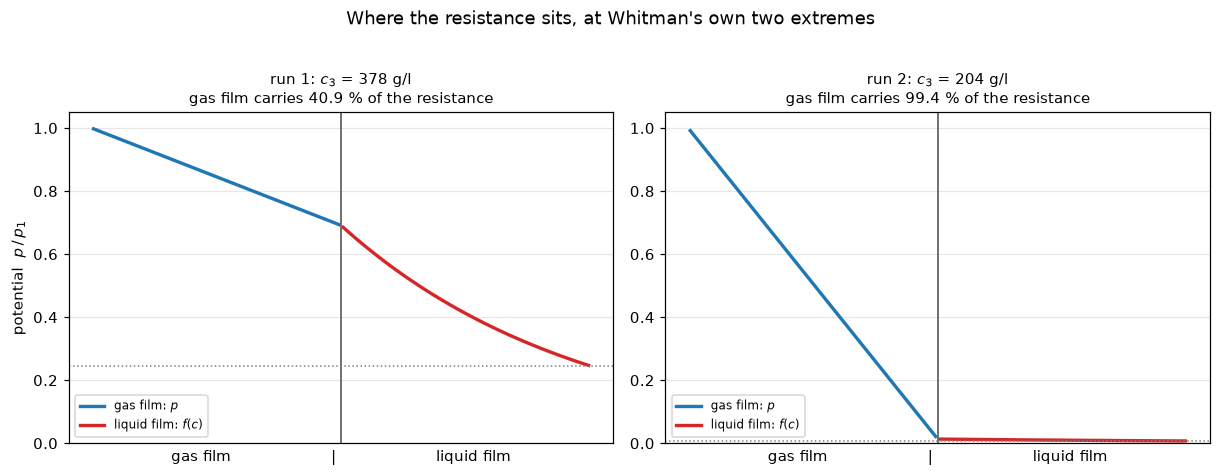

In [15]:
# The classical two-film diagram: ONE potential across both films. In the gas
# film that is the partial pressure itself; in the liquid film it is the
# pressure the local concentration would exert, f(c). The two meet at the
# interface by construction, so the drop across each film is directly readable.
fig, axes = plt.subplots(1, 2, figsize=(11.2, 4.2))
for ax, run in zip(axes, (1, 2)):
    tf = TwoFilm(KP_R3, KC_1, EQ.p, EQ.dpdc, n=60)
    s = tf.solve(P1[run], C3[run])
    x_c = 0.5 * (tf.x_f[1:] + tf.x_f[:-1])
    ax.plot(x_c, s["p"] / P1[run], "-", lw=2.2, color="C0", label="gas film: $p$")
    ax.plot(1 + x_c, EQ.p(s["c"]) / P1[run], "-", lw=2.2, color="C3",
            label=r"liquid film: $f(c)$")
    ax.axvline(1.0, color="0.4", lw=1.2)
    ax.axhline(float(EQ.p(C3[run])) / P1[run], ls=":", lw=1, color="0.5")
    ax.set_xlabel("gas film                    |                    liquid film")
    ax.set_ylim(0, 1.05)
    ax.set_title(f"run {run}: $c_3$ = {C3[run]:g} g/l\ngas film carries "
                 f"{100 * resistance_share(EQ, KC_1, run):.1f} % of the resistance", fontsize=10)
    ax.set_xticks([])
    ax.legend(fontsize=8, loc="lower left")
axes[0].set_ylabel(r"potential  $p\,/\,p_1$")
fig.suptitle("Where the resistance sits, at Whitman's own two extremes", y=1.02)
fig.tight_layout()
plt.show()

### 3. The three runs against three models

This is the comparison with power. Three published rates; three candidate
models, each fitted to all three runs by least squares on the *relative* residual
in $\mathrm{d}W/\mathrm{d}\theta$:

- **single gas film**, eq. (5) with a constant $K_p = k_p$: one parameter;
- **single liquid film**, eq. (6) with a constant $K_c = k_c$: one parameter;
- **two films**, eq. (4) closed with the reconstructed equilibrium curve: two
  parameters, so **one degree of freedom** remains.

**Two of these three numbers were settled before any physics entered, and the
page should say which.** The two-film family *nests* the single-gas-film model:
$k_c \to \infty$ is eq. (5) with the back pressure taken from the equilibrium
curve instead of from Table 1's $p_3$ column. Its second parameter is then free
to absorb run 1, the only run with a real liquid resistance, and it does, to a
residual of a few thousandths of a per cent. So the three-run rms is set by
runs 2 and 3, and their mutual consistency under *one* gas coefficient is
already printed in Table 1, as the same $K_p$ for both. The two-film rms could
not have come out at tens of per cent.

What could fail is the one degree of freedom that is left over, and section 4
shows that it does, and that the liquid film makes it *worse*.

In [16]:
def rel_resid_two(theta, kc=None, subset=(1, 2, 3), runs=RUNS, eq=EQ):
    kp = np.exp(theta[0])
    kcv = np.exp(theta[1]) if kc is None else kc
    return [two_film_algebraic(r["p1_mmHg"], r["c3_g_per_l"], kp, kcv, eq.p)["N"]
            / r["dW_dtheta_g_per_h"] - 1 for r in runs if int(r["run"]) in subset]


def rel_resid_gas(theta, subset=(1, 2, 3), runs=RUNS):
    kp = np.exp(theta[0])
    return [kp * (r["p1_mmHg"] - r["p3_mmHg"]) / r["dW_dtheta_g_per_h"] - 1
            for r in runs if int(r["run"]) in subset]


def rel_resid_nolf(theta, subset=(1, 2, 3), runs=RUNS, eq=EQ):
    """The two-film family's k_c -> infinity member: one parameter, k_p."""
    kp = np.exp(theta[0])
    return [no_liquid_film_rate(r["p1_mmHg"], r["c3_g_per_l"], kp, eq.p)["N"]
            / r["dW_dtheta_g_per_h"] - 1 for r in runs if int(r["run"]) in subset]


def rel_resid_liq(theta, runs=RUNS):
    kc = np.exp(theta[0])
    return [kc * (r["c1_g_per_l"] - r["c3_g_per_l"]) / r["dW_dtheta_g_per_h"] - 1
            for r in runs]


def fit(f, x0):
    s = least_squares(f, x0)
    r = np.asarray(f(s.x))
    return np.exp(s.x), r, float(np.sqrt((r ** 2).mean()))


par_g, res_g, rms_g = fit(rel_resid_gas, [np.log(0.4)])
par_l, res_l, rms_l = fit(rel_resid_liq, [np.log(0.3)])
par_2, res_2, rms_2 = fit(rel_resid_two, np.log([0.59, 1.2]))
display(pd.DataFrame([
    dict(model="single gas film, eq. (5)", n_par=1, fitted=f"k_p = {par_g[0]:.4f}",
         rms_pct=100 * rms_g, worst_pct=100 * np.abs(res_g).max()),
    dict(model="single liquid film, eq. (6)", n_par=1, fitted=f"k_c = {par_l[0]:.4f}",
         rms_pct=100 * rms_l, worst_pct=100 * np.abs(res_l).max()),
    dict(model="two films, eq. (4)", n_par=2,
         fitted=f"k_p = {par_2[0]:.4f}, k_c = {par_2[1]:.4f}",
         rms_pct=100 * rms_2, worst_pct=100 * np.abs(res_2).max())]).round(3))
print("per-run relative residuals, %")
print(f"   single gas film    {np.round(100 * res_g, 2)}")
print(f"   single liquid film {np.round(100 * res_l, 2)}")
print(f"   two films          {np.round(100 * res_2, 3)}")
print(f"\nTable 1's own precision on a rate is +-{100 * RATE_HALF_UNIT / OBS[2]:.2f} %.")
print("A single film, either one, misses by tens of per cent. Two films do not.")
claims.value("gasfilm_3run_rms_pct", 100 * rms_g, rtol=1e-3)
claims.value("liquidfilm_3run_rms_pct", 100 * rms_l, rtol=1e-3)
claims.value("twofilm_3run_rms_pct", 100 * rms_2, rtol=1e-3)
claims.value("gasfilm_3run_worst_pct", 100 * np.abs(res_g).max(), rtol=1e-3)
claims.value("liquidfilm_3run_worst_pct", 100 * np.abs(res_l).max(), rtol=1e-3)
claims.value("twofilm_3run_worst_pct", 100 * np.abs(res_2).max(), rtol=1e-3)
claims.value("twofilm_run1_resid_pct", 100 * abs(res_2[0]), rtol=0.05)

,model,n_par,fitted,rms_pct,worst_pct
0,"single gas film, eq. (5)",1,k_p = 0.3285,41.708,44.289
1,"single liquid film, eq. (6)",1,k_c = 0.0848,59.474,90.284
2,"two films, eq. (4)",2,"k_p = 0.5905, k_c = 1.1837",0.379,0.470


per-run relative residuals, %
   single gas film    [ 36.21 -44.29 -44.11]
   single liquid film [-90.28 -42.08  26.25]
   two films          [ 0.005 -0.47   0.46 ]

Table 1's own precision on a rate is +-0.21 %.
A single film, either one, misses by tens of per cent. Two films do not.


#### How much of the two-film rms was available to fail

Run 1's two-film residual is the smallest of the three, because $k_c$ is the
parameter that fits it. Strip run 1 out and what remains is a **two-point,
one-parameter** problem, whose residual is fixed by how well runs 2 and 3 agree
under a single gas coefficient: a number Table 1 prints directly, as $K_p$
twice.

In [17]:
KP_COL = {run: OBS[run] / float(R[run]["delta_p_mmHg"]) for run in (2, 3)}
RUNS23_KP_DISAGREE = KP_COL[2] / KP_COL[3] - 1
print(f"Table 1's K_p column, recomputed: run 2 {KP_COL[2]:.5f}, run 3 {KP_COL[3]:.5f}, "
      f"both printed as {R[2]['K_p']}")
print(f"   they disagree by {100 * RUNS23_KP_DISAGREE:.3f} %, and that is the whole budget")
print("   any one-parameter gas model has to work with on these two runs.\n")
par_g23, res_g23, rms_g23 = fit(lambda th: rel_resid_gas(th, subset=(2, 3)), [np.log(0.59)])
par_n23, res_n23, rms_n23 = fit(lambda th: rel_resid_nolf(th, subset=(2, 3)), [np.log(0.59)])
res_2_23 = np.asarray(res_2)[[1, 2]]
TWOFILM_RUNS23_RMS = float(np.sqrt((res_2_23 ** 2).mean()) * 100)
display(pd.DataFrame([
    dict(model="single gas film, eq. (5), printed p3", n_par=1,
         fitted=f"k_p = {par_g23[0]:.5f}", rms_pct=100 * rms_g23,
         resid_run2_pct=100 * res_g23[0], resid_run3_pct=100 * res_g23[1]),
    dict(model="liquid film DELETED (k_c -> inf), f(c3)", n_par=1,
         fitted=f"k_p = {par_n23[0]:.5f}", rms_pct=100 * rms_n23,
         resid_run2_pct=100 * res_n23[0], resid_run3_pct=100 * res_n23[1]),
    dict(model="two films (k_p, k_c fitted to all three)", n_par=2,
         fitted=f"k_p = {par_2[0]:.5f}, k_c = {par_2[1]:.5f}", rms_pct=TWOFILM_RUNS23_RMS,
         resid_run2_pct=100 * res_2_23[0], resid_run3_pct=100 * res_2_23[1])]).round(4))
KP_F, KC_F = par_2
FIT_R2 = two_film_algebraic(P1[2], C3[2], KP_F, KC_F, EQ.p)
print(f"On the only two runs that constrain k_p, a ONE-parameter gas film fits to "
      f"{100 * rms_g23:.3f} % rms")
print(f"and the two-parameter two-film model to {TWOFILM_RUNS23_RMS:.3f} %, "
      f"{TWOFILM_RUNS23_RMS / (100 * rms_g23):.2f} times worse.")
print("Adding the liquid film degrades these two runs, because the fit to run 1 backs")
print(f"run 2's interface up from f(c3) = {float(EQ.p(C3[2])):.3f} to "
      f"{FIT_R2['p2']:.3f} mmHg.")
claims.value("gasfilm_runs23_rms_pct", 100 * rms_g23, rtol=1e-3)
claims.value("nolf_runs23_rms_pct", 100 * rms_n23, rtol=1e-3)
claims.value("twofilm_runs23_rms_pct", TWOFILM_RUNS23_RMS, rtol=1e-3)
claims.value("twofilm_fit_run2_p2_mmHg", FIT_R2["p2"], rtol=1e-3)

Table 1's K_p column, recomputed: run 2 0.58968, run 3 0.58780, both printed as 0.59
   they disagree by 0.319 %, and that is the whole budget
   any one-parameter gas model has to work with on these two runs.



,model,n_par,fitted,rms_pct,resid_run2_pct,resid_run3_pct
0,"single gas film, eq. (5), printed p3",1,k_p = 0.58874,0.1593,-0.1596,0.1590
1,"liquid film DELETED (k_c -> inf), f(c3)",1,k_p = 0.58875,0.1584,-0.1587,0.1582
2,"two films (k_p, k_c fitted to all three)",2,"k_p = 0.59053, k_c = 1.18367",0.4647,-0.4696,0.4598


On the only two runs that constrain k_p, a ONE-parameter gas film fits to 0.159 % rms
and the two-parameter two-film model to 0.465 %, 2.92 times worse.
Adding the liquid film degrades these two runs, because the fit to run 1 backs
run 2's interface up from f(c3) = 0.300 to 0.549 mmHg.


### 4. Where the one degree of freedom lands, and it does not land cleanly

Three observations minus two parameters leaves one testable combination, and it
is essentially the **ratio of run 3's rate to run 2's**. Both runs share
$p_1$; they differ only in bulk liquid concentration. Two-film theory says run 3
must be the faster of the two, because run 2's interface backs up to a finite
partial pressure and run 3's does not. The question is by how much.

$k_p$ cancels out of a ratio of two runs at the same $p_1$, so three of the
four predictions below contain **no fitted parameter at all**: they are
properties of the model, not of the fit. That makes this the cleanest
comparison the data allow.

In [18]:
def dof_ratios(eq=EQ, kc=KC_F, kp=KP_F, runs=R):
    """run3/run2 rate ratio: observed, and as four models predict it."""
    p1_2, p1_3 = runs[2]["p1_mmHg"], runs[3]["p1_mmHg"]
    c3_2, c3_3 = runs[2]["c3_g_per_l"], runs[3]["c3_g_per_l"]
    two = (two_film_algebraic(p1_3, c3_3, kp, kc, eq.p)["N"]
           / two_film_algebraic(p1_2, c3_2, kp, kc, eq.p)["N"])
    return dict(
        observed=runs[3]["dW_dtheta_g_per_h"] / runs[2]["dW_dtheta_g_per_h"],
        none=p1_3 / p1_2,
        gas=(p1_3 - runs[3]["p3_mmHg"]) / (p1_2 - runs[2]["p3_mmHg"]),
        nolf=(no_liquid_film_rate(p1_3, c3_3, kp, eq.p)["N"]
              / no_liquid_film_rate(p1_2, c3_2, kp, eq.p)["N"]),
        two=two)


RAT = dof_ratios()
PREC_RATIO = 100 * np.hypot(RATE_HALF_UNIT / OBS[2], RATE_HALF_UNIT / OBS[3])
labels = dict(none=("no back pressure at all", "no parameters"),
              gas=("single gas film, eq. (5), Table 1's p3", "no parameters"),
              nolf=("liquid film deleted, back pressure from f(c3)", "no parameters (k_p cancels)"),
              two=("two films, fitted k_c", "k_c enters; k_p cancels"))
display(pd.DataFrame([dict(model=labels[k][0], run3_over_run2=RAT[k],
                           dev_vs_table1_pct=100 * (RAT[k] / RAT["observed"] - 1),
                           free=labels[k][1]) for k in labels]).round(5))
DOF_OVERPRED_PCT = 100 * (RAT["two"] / RAT["observed"] - 1)
GASFILM_DOF_PCT = 100 * (RAT["gas"] / RAT["observed"] - 1)
GAP_FRACTION = (RAT["observed"] - 1) / (RAT["two"] - 1)
print(f"Table 1:  run3/run2 = {RAT['observed']:.5f}, printed precision +-{PREC_RATIO:.2f} %")
print(f"The observed gap sits BETWEEN no back pressure "
      f"({100 * (RAT['none'] / RAT['observed'] - 1):+.3f} %) and a gas film alone "
      f"({GASFILM_DOF_PCT:+.3f} %).")
print(f"The two-film model over-predicts it by {DOF_OVERPRED_PCT:+.3f} %: the observed gap "
      f"is {GAP_FRACTION:.2f} of the predicted one.")
KP_IDENTITY = abs(GASFILM_DOF_PCT / 100 - RUNS23_KP_DISAGREE)
print(f"\n{GASFILM_DOF_PCT:+.3f} % is the {100 * RUNS23_KP_DISAGREE:.3f} % by which Table 1's "
      "two K_p, recomputed from its delta_p column, disagree (gap below 1e-12, "
      f"here {KP_IDENTITY:.1e}):")
print("K_p(run 2)/K_p(run 3) = (N2/N3)(dp3/dp2). One number, seen twice.")
claims.value("ratio_observed_run3_over_run2", RAT["observed"], rtol=1e-5)
claims.value("ratio_twofilm_run3_over_run2", RAT["two"], rtol=1e-5)
claims.value("ratio_gasfilm_run3_over_run2", RAT["gas"], rtol=1e-5)
claims.value("ratio_nolf_run3_over_run2", RAT["nolf"], rtol=1e-5)
claims.value("dof_ratio_overpredict_pct", DOF_OVERPRED_PCT, rtol=1e-3)
claims.value("gasfilm_dof_ratio_dev_pct", GASFILM_DOF_PCT, rtol=1e-3)
claims.value("dof_gap_fraction", GAP_FRACTION, rtol=1e-3)
claims.bound("kp_disagreement_is_gasfilm_dof", KP_IDENTITY, max=1e-12, basis="identity",
             note="K_p(2)/K_p(3) - 1 and the gas-film ratio deviation "
             "are the same expression")
print("\nand the ratio barely depends on k_c, so this test does not probe it either:")
for lab, k in [(f"{KC_F:9.4g}", KC_F), (f"{5 * KC_F:9.4g}", 5 * KC_F)]:
    print(f"     k_c = {lab}   run3/run2 = {dof_ratios(kc=k)['two']:.5f}")
print(f"     k_c = infinity    run3/run2 = {RAT['nolf']:.5f}")

,model,run3_over_run2,dev_vs_table1_pct,free
0,no back pressure at all,1.00000,-0.41494,no parameters
1,"single gas film, eq. (5), Table 1's p3",1.00737,0.31910,no parameters
2,"liquid film deleted, back pressure from f(c3)",1.00735,0.31739,no parameters (k_p cancels)
3,"two films, fitted k_c",1.01354,0.93380,k_c enters; k_p cancels


Table 1:  run3/run2 = 1.00417, printed precision +-0.29 %
The observed gap sits BETWEEN no back pressure (-0.415 %) and a gas film alone (+0.319 %).
The two-film model over-predicts it by +0.934 %: the observed gap is 0.31 of the predicted one.

+0.319 % is the 0.319 % by which Table 1's two K_p, recomputed from its delta_p column, disagree (gap below 1e-12, here 2.2e-16):
K_p(run 2)/K_p(run 3) = (N2/N3)(dp3/dp2). One number, seen twice.

and the ratio barely depends on k_c, so this test does not probe it either:
     k_c =     1.184   run3/run2 = 1.01354
     k_c =     5.918   run3/run2 = 1.00831
     k_c = infinity    run3/run2 = 1.00735


So the single quantitative test the data offer is **not passed cleanly**: the
observed gap between runs 2 and 3 is about a third of the predicted one, a
discrepancy of order 1 % against a printed precision of order 0.3 %. It is far
too small to refute anything (Whitman quotes no experimental error, and 1 % on
a 1923 absorption rate is nothing), but it is worth being exact about what it
says. On **both** quantities the three runs can actually test (the held-out
run-2 rate of section 2, and this ratio) the two-film model is beaten by the
same model with the liquid film taken out, which has one parameter fewer. That
is the same finding twice, and it points the same way as everything else on
this page: **the data show less liquid-film effect than the theory needs.**

### 5. What the three runs can say about the liquid-film coefficient, and what they cannot

Profile the fit: fix $k_c$, re-fit $k_p$, and look at the residual. Do it for
every subset of two or three runs. The band of $k_c$ a subset admits is where
its rms stays below 2 %, about ten times Table 1's own precision on a rate; its
edges are root-found on the profile, not read off the sweep.

  all three runs                : k_c admitted at rms <= 2 %: [1.13, 1.244]


  runs 1 and 2                  : k_c admitted at rms <= 2 %: [1.13, 1.232]


  runs 1 and 3                  : k_c admitted at rms <= 2 %: [1.14, 1.237]


  runs 2 and 3, run 1 REMOVED   : k_c admitted at rms <= 2 %: [0.396, inf]  still below 2 % at the top of the sweep

  every subset containing run 1 admits k_c only in [1.126, 1.244]; with all three runs the band spans a factor 1.1048
  with run 1 removed the band starts at 0.396; upper end none: the profile has 0 rises in 159 steps
  towards its k_c -> infinity limit, the deleted-film fit, 0.158 % rms


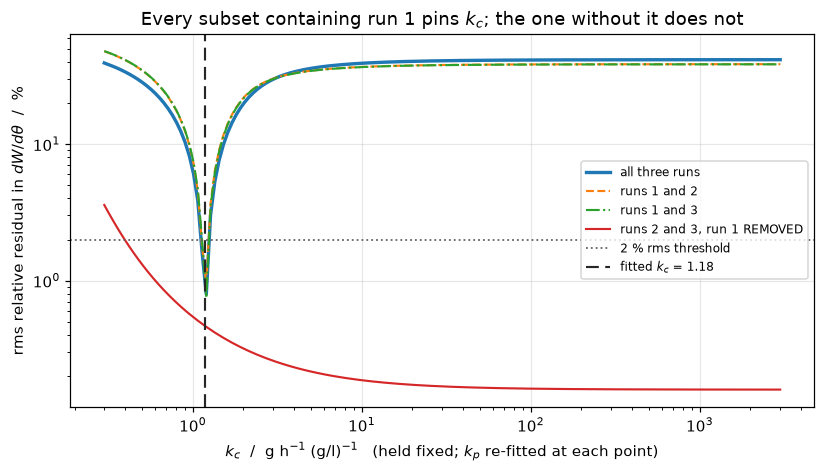

In [19]:
THRESH = 0.02                           # 2 % rms
KC_SWEEP = np.geomspace(0.3, 3e3, 160)


def profile_rms(kc, subset, runs=RUNS, eq=EQ):
    """rms relative residual with k_c fixed and k_p re-fitted."""
    s = least_squares(lambda th: rel_resid_two(th, kc=kc, subset=subset, runs=runs, eq=eq),
                      [np.log(0.59)], xtol=1e-14, ftol=1e-14, gtol=1e-14)
    r = np.asarray(rel_resid_two(s.x, kc=kc, subset=subset, runs=runs, eq=eq))
    return float(np.sqrt((r ** 2).mean()))


def kc_band(subset, runs=RUNS, eq=EQ):
    """Root-found edges of {k_c: profile rms <= THRESH}; the upper edge is inf when the
    rms is still below THRESH at the top of the sweep."""
    v = np.array([profile_rms(k, subset, runs, eq) for k in KC_SWEEP]) - THRESH
    inside = np.flatnonzero(v <= 0)
    if inside.size == 0:
        return np.nan, np.nan, v + THRESH
    i, j = inside[0], inside[-1]
    if not np.all(v[i:j + 1] <= 0):
        raise ValueError(f"the admitted set of {subset} is not one interval")

    def g(k):
        return profile_rms(k, subset, runs, eq) - THRESH

    lo = KC_SWEEP[0] if i == 0 else brentq(g, KC_SWEEP[i - 1], KC_SWEEP[i], xtol=1e-12)
    hi = np.inf if j == len(KC_SWEEP) - 1 else brentq(g, KC_SWEEP[j], KC_SWEEP[j + 1],
                                                     xtol=1e-12)
    return lo, hi, v + THRESH


SUBSETS = [((1, 2, 3), "all three runs"), ((1, 2), "runs 1 and 2"),
           ((1, 3), "runs 1 and 3"), ((2, 3), "runs 2 and 3, run 1 REMOVED")]
BANDS, PROF = {}, {}
for sub, lab in SUBSETS:
    lo, hi, PROF[sub] = kc_band(sub)
    BANDS[sub] = (lo, hi)
    top = ("  still below 2 % at the top of the sweep" if not np.isfinite(hi) else "")
    print(f"  {lab:30s}: k_c admitted at rms <= {100 * THRESH:.0f} %: "
          f"[{lo:.3g}, {hi:.4g}]{top}")
WITH_RUN1 = [s for s, _ in SUBSETS if 1 in s]
KC_LO_RUN1 = min(BANDS[s][0] for s in WITH_RUN1)
KC_HI_RUN1 = max(BANDS[s][1] for s in WITH_RUN1)
KC_BAND_WIDTH_ALL = BANDS[(1, 2, 3)][1] / BANDS[(1, 2, 3)][0]
P23 = PROF[(2, 3)]
print(f"\n  every subset containing run 1 admits k_c only in [{KC_LO_RUN1:.3f}, "
      f"{KC_HI_RUN1:.3f}]; with all three runs the band spans a factor "
      f"{KC_BAND_WIDTH_ALL:.4f}")
UNBOUNDED_NO1 = bool(np.isinf(BANDS[(2, 3)][1]))
RISES_NO1 = int(np.sum(np.diff(P23) > 0))
print(f"  with run 1 removed the band starts at {BANDS[(2, 3)][0]:.3f}; upper end "
      f"{'none' if UNBOUNDED_NO1 else 'finite'}: the profile has {RISES_NO1} rises in "
      f"{len(P23) - 1} steps")
print(f"  towards its k_c -> infinity limit, the deleted-film fit, {100 * rms_n23:.3f} % rms")
claims.exact("kc_band_without_run1_unbounded", UNBOUNDED_NO1)
claims.exact("profile_without_run1_rises", RISES_NO1)
claims.value("kc_band_low_all_runs", BANDS[(1, 2, 3)][0], rtol=1e-4)
claims.value("kc_band_high_all_runs", BANDS[(1, 2, 3)][1], rtol=1e-4)
claims.value("kc_band_width_all_runs", KC_BAND_WIDTH_ALL, rtol=1e-4)
claims.value("kc_band_low_run1_subsets", KC_LO_RUN1, rtol=1e-4)
claims.value("kc_band_high_run1_subsets", KC_HI_RUN1, rtol=1e-4)
claims.value("kc_band_low_without_run1", BANDS[(2, 3)][0], rtol=1e-4)

fig, ax = plt.subplots(figsize=(7.6, 4.4))
for (sub, lab), st in zip(SUBSETS, ["-", "--", "-.", "-"]):
    ax.loglog(KC_SWEEP, 100 * PROF[sub], st, lw=2.2 if len(sub) != 2 else 1.4, label=lab)
ax.axhline(100 * THRESH, ls=":", lw=1.2, color="0.4",
           label=f"{100 * THRESH:.0f} % rms threshold")
ax.axvline(KC_F, ls=(0, (6, 3)), lw=1.4, color="0.15", label=f"fitted $k_c$ = {KC_F:.2f}")
ax.set_xlabel(r"$k_c$  /  g h$^{-1}$ (g/l)$^{-1}$   (held fixed; $k_p$ re-fitted at each point)")
ax.set_ylabel(r"rms relative residual in $dW/d\theta$  /  %")
ax.set_title("Every subset containing run 1 pins $k_c$; the one without it does not")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

**Run 1 is the only run that carries information about $k_c$.** Every subset
that contains it pins the coefficient to within about 5 %; the subset that
does not admits every value above its lower edge, because its profile falls
towards the deleted-film fit, which is far inside the threshold. The remaining
data are consistent with an infinitely fast liquid film.

That distinction matters and it is easy to blur. $k_c$ is tightly *identified*:
one equation, one unknown, and a narrow band. It is not *tested*: the narrowness
is entirely run 1's doing, and run 1 is precisely the run Whitman fits $k_c$ to.
So the liquid-film coefficient of the two-film theory is, in this paper,
determined by one observation and corroborated by none.

That is a quantitative form of the remark the 1962 Foreword quotes from Sherwood
and Pigford. It is not a criticism of Whitman, who says the same thing in
plainer words across reprint pages 432–433 (the data "are insufficient to prove
definitely the truth of the two-film theory") and calls his own paper "A
Preliminary Experimental Confirmation".

What the data *do* establish, and it is not nothing: **a single film of either
kind cannot describe these three runs**, by tens of per cent, and a two-film
description can. The qualitative claim survives; the quantitative liquid-film
coefficient is untested.

### 6. Where resistance additivity breaks: the textbook formula

The form everyone actually uses is not eq. (4) but its linearised child. With
Henry's law $p = m\,c$, eliminating $p_2 = m\,c_2$ from eq. (4) gives

$$\frac{1}{K_p} = \frac{1}{k_p} + \frac{m}{k_c},\qquad m = \frac{\mathrm{d}p}{\mathrm{d}c},$$

which requires a **single** $m$. Whitman says this is exactly what fails: "if
the deviation from Henry's law … is considerable, a simplification based on
direct proportionality between $p$ and $c$ would be unjustified and the overall
coefficients $K_c$ or $K_p$ would have no significance."

Below, that formula is evaluated with the two most defensible choices of $m$
(the tangent slope at the bulk liquid concentration, and the secant of the
reconstructed curve across the run's own span from $c_3$ to $c_1$) and
compared with the exact non-linear interface solve at the same $k_p$, $k_c$.
Two checks bracket it. With a linear equilibrium both choices are exact; the
break table puts that in. And with the chord from $c_3$ to the solved
interface $c_2$ it is exact on the real curve too, an identity, since that
chord is what eq. (4) eliminates; but $c_2$ is only known after the solve.
So the errors below are the curvature of the equilibrium line between $c_3$
and the point $m$ is taken at.

In [20]:
def additivity_errors(eq, kp=KP_R3, kc=KC_1, runs=RUNS, form="m/k_c"):
    """Error (%) of 1/K_p = 1/k_p + m/k_c per run, with the tangent, the secant
    across c3 to c1 and the chord from c3 to the solved interface c2.
    ``form="1/(m k_c)"`` writes the liquid term upside down (a break row only)."""
    rows = []
    for r in runs:
        p1, c1, c3 = r["p1_mmHg"], r["c1_g_per_l"], r["c3_g_per_l"]
        ex = two_film_algebraic(p1, c3, kp, kc, eq.p)
        K_exact = ex["N"] / (p1 - float(eq.p(c3)))
        m = dict(tangent=float(eq.dpdc(c3)),
                 secant=(float(eq.p(c1)) - float(eq.p(c3))) / (c1 - c3),
                 chord=(ex["p2"] - float(eq.p(c3))) / (ex["c2"] - c3))
        row = dict(run=int(r["run"]), K_p_exact=K_exact)
        for k, v in m.items():
            row[f"m_{k}"] = v
            liquid = v / kc if form == "m/k_c" else 1.0 / (v * kc)
            row[f"err_{k}_pct"] = 100 * (1.0 / (1.0 / kp + liquid) / K_exact - 1)
        rows.append(row)
    return pd.DataFrame(rows)


add = additivity_errors(EQ)
display(add.round(4))
CONSTH_R1_TAN = abs(add.err_tangent_pct.iloc[0])
CONSTH_R1_SEC = abs(add.err_secant_pct.iloc[0])
CONSTH_SEC_MAX = float(np.abs(add.err_secant_pct).max())
CONSTH_TAN_23 = float(np.abs(add.err_tangent_pct.iloc[1:]).max())
CHORD_IDENTITY = float(np.abs(add.err_chord_pct).max()) / 100
EQ_HALF = Equilibrium(EQ.A + 0.5 * EQ.B * np.mean(C_EQ), 0.5 * EQ.B)  # half the slope, same centroid
add_half = additivity_errors(EQ_HALF)
print(f"run 1, the only run with a real liquid resistance: the formula is off by "
      f"{add.err_tangent_pct.iloc[0]:+.1f} % (tangent m) and "
      f"{add.err_secant_pct.iloc[0]:+.1f} % (secant m).")
print(f"worst over all three runs, secant m: {CONSTH_SEC_MAX:.1f} %")
print(f"with the equilibrium slope halved (same centroid) run 1's errors fall to "
      f"{add_half.err_tangent_pct.iloc[0]:+.1f} % and {add_half.err_secant_pct.iloc[0]:+.1f} %")
print(f"runs 2 and 3 are gas-controlled: m/k_c is small against 1/k_p, and the tangent "
      f"is off by at most {CONSTH_TAN_23:.2f} %;")
print("the secant, taken across the large span up to c1, still overestimates m there.")
print(f"with the chord from c3 to the solved interface the formula is exact: below 1e-12 "
      f"(here {CHORD_IDENTITY:.1e})")
print(f"\nThe equilibrium curve rises tenfold every {1 / EQ.B:.1f} g/l; run 1's own "
      f"concentration span is {R[1]['c1_g_per_l'] - R[1]['c3_g_per_l']:g} g/l.")
claims.value("constH_run1_tangent_err_pct", CONSTH_R1_TAN, rtol=1e-3)
claims.value("constH_run1_secant_err_pct", CONSTH_R1_SEC, rtol=1e-3)
claims.value("constH_secant_worst_err_pct", CONSTH_SEC_MAX, rtol=1e-3)
claims.value("constH_runs23_tangent_worst_err_pct", CONSTH_TAN_23, rtol=1e-3)
claims.value("constH_halfslope_run1_tangent_err_pct", abs(add_half.err_tangent_pct.iloc[0]),
             rtol=1e-3)
claims.value("constH_halfslope_run1_secant_err_pct", abs(add_half.err_secant_pct.iloc[0]),
             rtol=1e-3)
claims.bound("constH_interface_chord_identity", CHORD_IDENTITY, max=1e-12, basis="identity",
             note="the chord from c3 to c2 is what eq. (4) eliminates")
claims.value("eq_gl_per_decade", 1 / EQ.B, rtol=1e-3)

,run,K_p_exact,m_tangent,err_tangent_pct,m_secant,err_secant_pct,m_chord,err_chord_pct
0,1,0.2413,1.651,34.1299,3.6208,-12.8179,2.8994,-0.0
1,2,0.5864,0.009,0.1664,0.2472,-10.4197,0.0123,-0.0
2,3,0.5900,0.000,0.0005,0.1138,-5.3631,0.0000,0.0


run 1, the only run with a real liquid resistance: the formula is off by +34.1 % (tangent m) and -12.8 % (secant m).
worst over all three runs, secant m: 12.8 %
with the equilibrium slope halved (same centroid) run 1's errors fall to +14.3 % and +4.9 %
runs 2 and 3 are gas-controlled: m/k_c is small against 1/k_p, and the tangent is off by at most 0.17 %;
the secant, taken across the large span up to c1, still overestimates m there.
with the chord from c3 to the solved interface the formula is exact: below 1e-12 (here 6.7e-16)

The equilibrium curve rises tenfold every 76.9 g/l; run 1's own concentration span is 47 g/l.


### 7. The overall coefficient is not a property of the apparatus

Same $k_p$, same $k_c$, same equipment. Only the operating point moves, over a
window of bulk concentrations and three gas pressures (Whitman's two and one
between). In this window $K_p$ falls and $K_c$ rises monotonically with $c_3$
at every $p_1$ (the steps against that trend are counted below), so the
extremes are corners of the window, not samples.

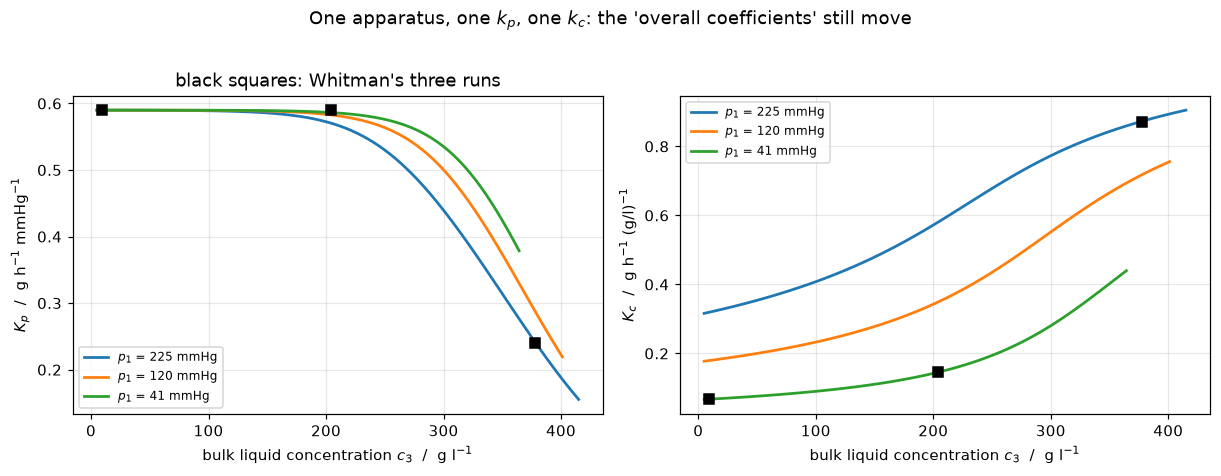

At fixed k_p = 0.59 and k_c = 1.184, over c3 = 5 to 415 g/l and p1 = [225.0, 120.0, 41.0] mmHg:
   K_p ranges over a factor 3.80 (0.1553 to 0.5900)
   K_c ranges over a factor 13.59 (0.06661 to 0.90501)
   steps against the monotone trend: 0 (the log-linear f is convex, so the
   chord slope from c3 to c2 grows with c3)


In [21]:
C3_WINDOW = np.linspace(5.0, 415.0, 90)
P1_WINDOW = sorted({P1[1], P1[2], 120.0}, reverse=True)


def overall_coefficients(eq=EQ, kp=KP_R3, kc=KC_1):
    """K_p and K_c over the window, the sampled points where f(c3) < p1."""
    out = {}
    for p1 in P1_WINDOW:
        c3s = C3_WINDOW[eq.p(C3_WINDOW) < p1]
        N = np.array([two_film_algebraic(p1, c, kp, kc, eq.p)["N"] for c in c3s])
        out[p1] = (c3s, N / (p1 - eq.p(c3s)), N / (eq.c(p1) - c3s))
    return out


def range_summary(out):
    kp_all = np.concatenate([v[1] for v in out.values()])
    kc_all = np.concatenate([v[2] for v in out.values()])
    rises = sum(int(np.sum(np.diff(v[1]) > 0)) + int(np.sum(np.diff(v[2]) < 0))
                for v in out.values())
    return kp_all.min(), kp_all.max(), kc_all.min(), kc_all.max(), rises


KOUT = overall_coefficients()
KP_MIN, KP_MAX, KC_MIN, KC_MAX, K_NONMONO = range_summary(KOUT)
fig, axes = plt.subplots(1, 2, figsize=(11.2, 4.2))
for p1, (c3s, Kp, Kc) in KOUT.items():
    axes[0].plot(c3s, Kp, lw=1.8, label=f"$p_1$ = {p1:.0f} mmHg")
    axes[1].plot(c3s, Kc, lw=1.8, label=f"$p_1$ = {p1:.0f} mmHg")
for r in RUNS:
    axes[0].plot(r["c3_g_per_l"], r["K_p"], "ks", ms=7, zorder=5)
    axes[1].plot(r["c3_g_per_l"], r["K_c"], "ks", ms=7, zorder=5)
axes[0].set_ylabel(r"$K_p$  /  g h$^{-1}$ mmHg$^{-1}$")
axes[1].set_ylabel(r"$K_c$  /  g h$^{-1}$ (g/l)$^{-1}$")
for ax in axes:
    ax.set_xlabel(r"bulk liquid concentration $c_3$  /  g l$^{-1}$")
    ax.legend(fontsize=8)
axes[0].set_title("black squares: Whitman's three runs")
fig.suptitle(r"One apparatus, one $k_p$, one $k_c$: the 'overall coefficients' still move",
             y=1.02)
fig.tight_layout()
plt.show()
KP_RANGE_FACTOR, KC_RANGE_FACTOR = KP_MAX / KP_MIN, KC_MAX / KC_MIN
print(f"At fixed k_p = {KP_R3} and k_c = {KC_1:.3f}, over c3 = {C3_WINDOW[0]:g} to "
      f"{C3_WINDOW[-1]:g} g/l and p1 = {P1_WINDOW} mmHg:")
print(f"   K_p ranges over a factor {KP_RANGE_FACTOR:.2f} ({KP_MIN:.4f} to {KP_MAX:.4f})")
print(f"   K_c ranges over a factor {KC_RANGE_FACTOR:.2f} ({KC_MIN:.5f} to {KC_MAX:.5f})")
print(f"   steps against the monotone trend: {K_NONMONO} (the log-linear f is convex, so the")
print("   chord slope from c3 to c2 grows with c3)")
claims.exact("K_window_nonmonotone_steps", K_NONMONO)
claims.value("Kp_range_factor", KP_RANGE_FACTOR, rtol=1e-3)
claims.value("Kc_range_factor", KC_RANGE_FACTOR, rtol=1e-3)
claims.value("Kp_min", KP_MIN, rtol=1e-3)
claims.value("Kp_max", KP_MAX, rtol=1e-4)
claims.value("Kc_min", KC_MIN, rtol=1e-3)
claims.value("Kc_max", KC_MAX, rtol=1e-3)

### 8. One thing the film model can do that the algebra cannot

The film is a *differential* object, and writing it as one buys a case the
algebra of eq. (4) cannot express: a first-order reaction in the liquid film.
The finite-volume solve is checked against the exact film profile
(`reacting_film_rate` in `model.py`: the hyperbolic-sine profile of a
reacting film, closed with the same equilibrium, a scalar root and no grid),
first at a moderate rate constant, where the reaction layer is resolved and the
scheme's second order shows, and then at a fast one.

As the rate constant grows the liquid side stops resisting: $c_2 \to 0$ and the
rate tends to $k_p\,(p_1 - f(0))$, the gas film alone working against the back
pressure of reactant-free liquid. On this page $f(0)$ is not zero: it is the
intercept $10^A$ of the reconstructed line, an extrapolation far below the
concentrations Table 1 covers. So the remaining gap to $k_p\,p_1$ is set by that
intercept, not by the grid: the finite-volume value converges to the exact film
value with $n$, and the exact value tends to $f(0)/p_1$ with the rate constant.
The break table tests the two candidate causes one at a time.

This is an illustration of the mechanism, not a result about HCl: Whitman
publishes no rate constant, and the enhancement regimes belong to
[`F3.1`](../F3.1-hatta-regimes/), which owns Hatta's paper.

In [22]:
KA_MOD, KA_FAST, N_REACT = 10.0, 1e6, 200
N_GASFILM_ONLY = KP_R3 * P1[1]
INTERCEPT_REL = float(EQ.p(0.0)) / P1[1]


def reacting_solve(ka, n, eq=EQ, **kw):
    return TwoFilm(KP_R3, KC_1, eq.p, eq.dpdc, n=n, ka=ka, **kw).solve(P1[1], C3[1])


rows = []
for ka in [0.0, 0.1, 1.0, KA_MOD, 1e3, KA_FAST]:
    s = reacting_solve(ka, N_REACT)
    ex = (two_film_algebraic(P1[1], C3[1], KP_R3, KC_1, EQ.p) if ka == 0 else
          reacting_film_rate(P1[1], C3[1], KP_R3, KC_1, ka, EQ.p, EQ.c))
    rows.append(dict(ka=ka, rate=s["N"], rate_exact_film=ex["N"], c2=s["c2"],
                     c2_exact_film=ex["c2"], one_minus_N_over_kp_p1=1 - s["N"] / N_GASFILM_ONLY))
display(pd.DataFrame(rows))

LADDER = (25, 50, 100)
ex_mod = reacting_film_rate(P1[1], C3[1], KP_R3, KC_1, KA_MOD, EQ.p, EQ.c)
ERR = np.array([abs(reacting_solve(KA_MOD, n)["N"] / ex_mod["N"] - 1) for n in LADDER])
ORDERS = np.log2(ERR[:-1] / ERR[1:])
# round-off of the same solve at the finest rung: the ka = 0 solve is exact there
ROUNDOFF = abs(TwoFilm(KP_R3, KC_1, EQ.p, EQ.dpdc, n=LADDER[-1]).solve(P1[1], C3[1])["N"]
               / two_film_algebraic(P1[1], C3[1], KP_R3, KC_1, EQ.p)["N"] - 1)


def ladder_guard(ref):
    """Finest-rung error against ``ref`` over the round-off of the same grid."""
    err = abs(reacting_solve(KA_MOD, LADDER[-1])["N"] / ref - 1)
    return err / max(ROUNDOFF, np.finfo(float).eps)


GUARD = ladder_guard(ex_mod["N"])
ERR_N200 = abs(reacting_solve(KA_MOD, N_REACT)["N"] / ex_mod["N"] - 1)
print(f"ka = {KA_MOD:g} (reaction layer resolved), rate against the exact film:")
for n, e in zip(LADDER, ERR):
    print(f"   n = {n:4d}   relative error {e:.3e}")
print(f"   observed orders {np.round(ORDERS, 3)}; finest error over the round-off of the "
      f"same grid at least 1e3 (here {GUARD:.0e})")
print(f"   at n = {N_REACT}: {ERR_N200:.2e}")
claims.value("reaction_vs_exact_film_n200", ERR_N200, rtol=0.05)
claims.bound("reaction_order_ka10", ORDERS[-1], min=1.9, max=2.1, basis="theory",
             note="second-order finite volumes, resolved reaction layer")
claims.bound("reaction_ladder_finest_over_roundoff", GUARD, min=1e3, basis="theory",
             note="finest-rung error over the round-off of the same grid (ka = 0 solve)")

ex_fast = reacting_film_rate(P1[1], C3[1], KP_R3, KC_1, KA_FAST, EQ.p, EQ.c)
FAST = {n: reacting_solve(KA_FAST, n) for n in (25, 50, 100, 200, 400, 800, 1600)}
REACTION_LIMIT_RELDEV = 1 - FAST[N_REACT]["N"] / N_GASFILM_ONLY
FAST_EXACT_RESID = 1 - ex_fast["N"] / N_GASFILM_ONLY
print(f"\nka = {KA_FAST:g}: reaction layer sqrt(k_c/ka) = {np.sqrt(KC_1 / KA_FAST):.1e} "
      "of the film")
print(f"   {'n':>5} {'1 - N/(k_p p1)':>15} {'c2 (g/l)':>10}")
for n, s in FAST.items():
    print(f"   {n:5d} {1 - s['N'] / N_GASFILM_ONLY:15.4e} {s['c2']:10.4f}")
print(f"   exact film {FAST_EXACT_RESID:11.4e} {ex_fast['c2']:10.4f}")
print(f"   f(0)/p1 = 10^A/p1 = {INTERCEPT_REL:.4e}: the limit as ka -> infinity")
print(f"\nThe residual converges with n to the exact film value; c2 at n = {N_REACT} is "
      f"{FAST[N_REACT]['c2'] / ex_fast['c2']:.2f} times the exact one, at n = 1600 "
      f"{FAST[1600]['c2'] / ex_fast['c2']:.3f} times,")
print("but c2 is far below the line's scale 1/B, so the rate barely sees it.")
claims.value("reaction_limit_reldev", REACTION_LIMIT_RELDEV, rtol=1e-3)
claims.value("reaction_fast_exact_film_resid", FAST_EXACT_RESID, rtol=1e-4)
claims.value("intercept_over_p1", INTERCEPT_REL, rtol=1e-3)
claims.value("fast_c2_n200_over_exact", FAST[N_REACT]["c2"] / ex_fast["c2"], rtol=1e-3)
claims.value("fast_c2_n1600_over_exact", FAST[1600]["c2"] / ex_fast["c2"], rtol=1e-4)

,ka,rate,rate_exact_film,c2,c2_exact_film,one_minus_N_over_kp_p1
0,0.0,41.000000,41.000000,412.627200,412.627200,0.691149
1,0.1,54.466668,54.466667,407.328738,407.328738,0.589705
2,1.0,121.878611,121.878640,341.430407,341.430317,0.081894
3,10.0,132.745741,132.745741,79.568367,79.567332,0.000032
4,1000.0,132.749559,132.749559,3.858590,3.857890,0.000003
5,1000000.0,132.749605,132.749606,0.238653,0.121997,0.000003


ka = 10 (reaction layer resolved), rate against the exact film:
   n =   25   relative error 6.338e-08
   n =   50   relative error 1.590e-08
   n =  100   relative error 3.978e-09
   observed orders [1.995 1.998]; finest error over the round-off of the same grid at least 1e3 (here 2e+05)
   at n = 200: 9.94e-10

ka = 1e+06: reaction layer sqrt(k_c/ka) = 1.1e-03 of the film
       n  1 - N/(k_p p1)   c2 (g/l)
      25      3.1112e-06     1.6855
      50      3.0341e-06     0.8483
     100      2.9968e-06     0.4352
     200      2.9792e-06     0.2387
     400      2.9718e-06     0.1557
     800      2.9694e-06     0.1290
    1600      2.9689e-06     0.1231
   exact film  2.9688e-06     0.1220
   f(0)/p1 = 10^A/p1 = 2.9580e-06: the limit as ka -> infinity

The residual converges with n to the exact film value; c2 at n = 200 is 1.96 times the exact one, at n = 1600 1.009 times,
but c2 is far below the line's scale 1/B, so the rate barely sees it.


## Validation

Checks, ranked by what they can detect, followed by the table that says so.

1. **Equilibrium consistency of Table 1**: four printed $(c,p)$ pairs, one
   two-parameter form, two degrees of freedom. *Can fail:* a single mis-read
   digit in any of eight table cells moves it. Corroborated by Table 1's own
   duplication of $c_1$ at the shared $p_1$, which involves no fit at all.
2. **Whitman's worked example, held out**: his printed numbers reproduced from
   Table 1 alone. *Can fail:* it depends on the reconstruction, on eqs. (4)
   and (7), and on the $K_p(\text{run 3}) = k_p$ assumption.
3. **The three-run model comparison**: one degree of freedom on the two-film
   fit. *Can fail,* and it does not pass: the one testable combination is off by
   about 1 %, three times what a one-parameter model achieves on it. Section 3
   states which part of the two-film rms was **not** free to fail.
4. **The headline computed twice**: the deleted-liquid-film rate from the
   closed form and from a Richardson extrapolation of the root solve at finite
   $k_c$. The two share the gas-side expression and no solver.
5. **The reacting film against its exact profile**: a genuine discretisation
   error, second order on a resolved layer, with the finest error well above
   round-off.
6. **pymrm against the algebra, and grid independence**: identities (port
   checks). A linear profile is exact in a conservative finite-volume scheme,
   so both test the assembly and nothing else. They do move for a wrong geometry index and for a
   missing equilibrium jump.

### What the break table below cannot do

Every row in it perturbs an input and checks that a number moves. That
establishes **sensitivity**, and sensitivity is not correctness: a row proves a
claim would notice *this* defect, and says nothing about whether the undefected
value is right. A baseline that is wrong rather than insensitive passes every
row it has. That is why the headline has a second route (check 4), the
reacting film an exact reference (check 5), and why section 2 shows the
liquid-side reading of eq. (4) exceeding its own limit, a defect no
perturbation would have found.

### The break table

Each row re-runs the affected computation with one thing deliberately wrong,
injected through the data, an argument or the equilibrium relation, and hands
the result to `claims.breaks`, which records whether that claim's own check
fails. Three kinds appear: **transcription defects** (the mid-dot decimal trap
this file's own OCR falls into, digit transpositions), **model defects** (a
wrong `nu`, the equilibrium jump removed, the Jacobian without the equilibrium
slope, an unconverged Newton solve, a linear equilibrium, the intercept of the
line removed) and **data defects** (a rate replaced by one that a single-film
model would fit). Rows that do not fail their claim are kept and printed: a
blind spot left unstated is an implicit claim.

In [23]:
def rec(t):
    """Table 1 by run number, for a defected copy."""
    return {int(r["run"]): r for r in t.to_dict("records")}


# ---- 1. transcription defects in Table 1
T_DP = t1.copy()
T_DP.loc[T_DP.run == 1, "delta_p_mmHg"] = 107.0                    # 170 transposed
brk("delta_p(run 1) 170 -> 107 (transposed)", "table1_diff_columns_max_dev",
    table1_consistency(T_DP)[0])
T_KC3 = t1.copy()
T_KC3.loc[T_KC3.run == 3, "K_c"] = 0.67                            # 0.067, lost mid-dot
brk("K_c(run 3) 0.067 -> 0.67 (lost mid-dot)", "table1_coef_columns_max_pct",
    table1_consistency(T_KC3)[1])
_r = stated_ratios(T_KC3)
brk("K_c(run 3) 0.067 -> 0.67 (lost mid-dot)", "prose_twelvefold_recomputed", _r[1])
brk("K_c(run 3) 0.067 -> 0.67 (lost mid-dot)", "prose_twofold_recomputed", _r[2])
T_KP1 = t1.copy()
T_KP1.loc[T_KP1.run == 1, "K_p"] = 0.42                            # 0.24 transposed
brk("K_p(run 1) 0.24 -> 0.42 (transposed)", "prose_Kp_ratio_recomputed", stated_ratios(T_KP1)[0])
T_C13 = t1.copy()
T_C13.loc[T_C13.run == 3, "c1_g_per_l"] = 386.0                    # 368 transposed
brk("c1(run 3) 368 -> 386 (transposed)", "c1_distinct_at_shared_p1",
    len(c1_values_at_shared_p1(T_C13)[1]))
brk("c1(run 3) 368 -> 386 (transposed)", "eq_curve_worst_resid_pct",
    Equilibrium.fit(*equilibrium_pairs(T_C13).T).residuals(*equilibrium_pairs(T_C13).T)[0])

# the mid-dot trap on the equilibrium pairs: p3(run 1) 55 read as 5.5
T_P31 = t1.copy()
T_P31.loc[T_P31.run == 1, "p3_mmHg"] = 5.5
_pairs = equilibrium_pairs(T_P31)
EQ_P31 = Equilibrium.fit(*_pairs.T)
_w = EQ_P31.residuals(*_pairs.T)
brk("p3(run 1) 55 -> 5.5 (lost mid-dot)", "eq_curve_worst_resid_pct", _w[0])
brk("p3(run 1) 55 -> 5.5 (lost mid-dot)", "eq_curve_worst_resid_gl", _w[1])
brk("p3(run 1) 55 -> 5.5 (lost mid-dot)", "fig3_axis_top_dev_log10", axis_box(EQ_P31)[2])
brk("p3(run 1) 55 -> 5.5 (lost mid-dot)", "intercept_over_p1", float(EQ_P31.p(0.0)) / P1[1])
for k, v in worked_chain(EQ_P31)[0].items():
    if k != "worked_p2_run1_dev_mmHg":
        brk("p3(run 1) 55 -> 5.5, curve refitted", k, v)
T_P32 = t1.copy()
T_P32.loc[T_P32.run == 2, "p3_mmHg"] = 3.0                         # 0.3 read as 3.0
EQ_P32 = Equilibrium.fit(*equilibrium_pairs(T_P32).T)
brk("p3(run 2) 0.3 -> 3.0 (lost mid-dot)", "eq_pairs_decades",
    np.log10(equilibrium_pairs(T_P32)[:, 1].max() / equilibrium_pairs(T_P32)[:, 1].min()))
brk("p3(run 2) 0.3 -> 3.0 (lost mid-dot)", "negligible_backpressure_mmHg",
    float(EQ_P32.p(C_NEG)))
_rat = dof_ratios(runs=rec(T_P32))
T_DP2 = t1.copy()
T_DP2.loc[T_DP2.run == 2, "delta_p_mmHg"] = 47.0                   # 40.7 misread
_R = rec(T_DP2)
_kpcol = {run: _R[run]["dW_dtheta_g_per_h"] / _R[run]["delta_p_mmHg"] for run in (2, 3)}
_rd = dof_ratios(runs=_R)
brk("delta_p(run 2) 40.7 -> 47.0 (misread)", "kp_disagreement_is_gasfilm_dof",
    abs((_rd["gas"] / _rd["observed"] - 1) - (_kpcol[2] / _kpcol[3] - 1)))
brk("p3(run 2) 0.3 -> 3.0 (lost mid-dot)", "gasfilm_dof_ratio_dev_pct",
    100 * (_rat["gas"] / _rat["observed"] - 1))
brk("p3(run 2) 0.3 -> 3.0 (lost mid-dot)", "ratio_gasfilm_run3_over_run2", _rat["gas"])

# ---- 2. the printed rounding of k_p
KP_UNR = OBS[3] / float(R[3]["delta_p_mmHg"])                      # K_p(run 3) unrounded
brk("k_p taken unrounded, not the printed K_p(run 3)", "worked_p2_run1_dev_mmHg",
    worked_chain(EQ, kp=KP_UNR)[0]["worked_p2_run1_dev_mmHg"])
brk("k_p taken unrounded, not the printed K_p(run 3)", "run2_rate_reldev_no_liquid_film",
    abs(no_liquid_film_rate(P1[2], C3[2], KP_UNR, EQ.p)["N"] / OBS[2] - 1))
_k = range_summary(overall_coefficients(kp=KP_UNR))
brk("k_p taken unrounded, not the printed K_p(run 3)", "Kp_max", _k[1])

# ---- 3. pymrm model defects
for lab, kw in [("construct_div nu = 1 instead of 0", dict(nu=1)),
                ("interface equilibrium removed (p2 = c2)", dict(jump=False))]:
    t = TwoFilm(KP_R3, KC_1, EQ.p, EQ.dpdc, n=40, **kw)
    brk(lab, "pymrm_vs_algebra_reldev",
        abs(t.solve(P1[1], C3[1])["N"] / t.algebraic(P1[1], C3[1])["N"] - 1))
brk("construct_div nu = 1 instead of 0", "grid_spread_rel_n3_to_n600", grid_spread(nu=1)[1])
brk("construct_div nu = 1 instead of 0", "reaction_vs_exact_film_n200",
    abs(reacting_solve(KA_MOD, N_REACT, nu=1)["N"] / ex_mod["N"] - 1))
brk("interface equilibrium removed (p2 = c2)", "reaction_limit_reldev",
    1 - reacting_solve(KA_FAST, N_REACT, jump=False)["N"] / N_GASFILM_ONLY)
_lff = dict(liquid_flux_factor=2.0)
_sl = TwoFilm(KP_R3, KC_1, EQ.p, EQ.dpdc, n=40, **_lff).solve(P1[1], C3[1])
brk(f"TwoFilm({', '.join(f'{k}={v}' for k, v in _lff.items())}): continuity row wrong",
    "interface_flux_continuity", abs(_sl["N_liquid_face"] / _sl["N_gas_face"] - 1))
_bad = TwoFilm(KP_R3, KC_1, EQ.p, EQ.dpdc, n=40)
_s1 = _bad.solve(P1[1], C3[1], maxfev=1, require_success=False)
brk("newton maxfev = 1 (unconverged)", "newton_worst_backward_error", _s1["backward_error"])
_nj = TwoFilm(KP_R3, KC_1, EQ.p, EQ.dpdc, n=40, exact_jacobian=False)
_snj = _nj.solve(P1[1], C3[1], require_success=False)
brk("Jacobian without the equilibrium slope f'(c2)", "newton_max_iterations",
    _snj["nit"] if _snj["success"] else np.inf)
# reacting_film_rate with c3 = 0 is the exact film with its c3/sinh(Ha) term dropped
_ref_bad = reacting_film_rate(P1[1], 0.0, KP_R3, KC_1, KA_MOD, EQ.p, EQ.c)["N"]
_err_bad = [abs(reacting_solve(KA_MOD, n)["N"] / _ref_bad - 1) for n in LADDER[-2:]]
brk("exact film without its c3/sinh(Ha) term (a wrong reference)", "reaction_order_ka10",
    np.log2(_err_bad[0] / _err_bad[1]))
brk(f"finest rung n = {LADDER[-1]} taken as the reference", "reaction_ladder_finest_over_roundoff",
    ladder_guard(reacting_solve(KA_MOD, LADDER[-1])["N"]))

# ---- 4. the curvature of the equilibrium, and the intercept
for k, v in [("constH_run1_tangent_err_pct", abs(add_half.err_tangent_pct.iloc[0])),
             ("constH_run1_secant_err_pct", abs(add_half.err_secant_pct.iloc[0])),
             ("constH_secant_worst_err_pct", float(np.abs(add_half.err_secant_pct).max())),
             ("constH_runs23_tangent_worst_err_pct",
              float(np.abs(add_half.err_tangent_pct.iloc[1:]).max())),
             ("eq_gl_per_decade", 1 / EQ_HALF.B)]:
    brk("equilibrium slope halved (flatter curve)", k, v)
_k = range_summary(overall_coefficients(eq=EQ_HALF))
for k, v in zip(("Kp_min", "Kc_min", "Kc_max", "Kp_range_factor", "Kc_range_factor"),
                (_k[0], _k[2], _k[3], _k[1] / _k[0], _k[3] / _k[2])):
    brk("equilibrium slope halved (flatter curve)", k, v)
for k, v in zip(("kc_band_low_all_runs", "kc_band_high_all_runs"), kc_band((1, 2, 3), eq=EQ_HALF)):
    brk("equilibrium slope halved (flatter curve)", k, v)
_b = [kc_band(s, eq=EQ_HALF)[:2] for s in WITH_RUN1]
brk("equilibrium slope halved (flatter curve)", "kc_band_low_run1_subsets", min(b[0] for b in _b))
brk("equilibrium slope halved (flatter curve)", "kc_band_high_run1_subsets", max(b[1] for b in _b))
brk("equilibrium slope halved (flatter curve)", "kc_band_low_without_run1",
    kc_band((2, 3), eq=EQ_HALF)[0])


class Henry:
    """A linear equilibrium p = m c through run 1's bulk pair: the formula is exact."""
    m = R[1]["p3_mmHg"] / R[1]["c3_g_per_l"]
    p = staticmethod(lambda c: Henry.m * np.asarray(c, float))
    dpdc = staticmethod(lambda c: Henry.m + 0.0 * np.asarray(c, float))


_lin = additivity_errors(Henry)
brk("liquid term written 1/(m k_c) instead of m/k_c", "constH_interface_chord_identity",
    float(np.abs(additivity_errors(EQ, form="1/(m k_c)").err_chord_pct).max()) / 100)
brk("linear equilibrium (Henry's law)", "constH_halfslope_run1_tangent_err_pct",
    abs(_lin.err_tangent_pct.iloc[0]))
brk("linear equilibrium (Henry's law)", "constH_halfslope_run1_secant_err_pct",
    abs(_lin.err_secant_pct.iloc[0]))
EQ_NO_INTERCEPT_P = lambda c: EQ.p(c) - EQ.p(0.0)                  # noqa: E731
_eq0 = type("NoIntercept", (), dict(p=staticmethod(EQ_NO_INTERCEPT_P), dpdc=staticmethod(EQ.dpdc),
                                    c=staticmethod(lambda p: EQ.c(p + EQ.p(0.0)))))
brk("equilibrium intercept removed, f(c) - f(0)", "reaction_limit_reldev",
    1 - reacting_solve(KA_FAST, N_REACT, eq=_eq0)["N"] / N_GASFILM_ONLY)
brk("equilibrium intercept removed, f(c) - f(0)", "reaction_fast_exact_film_resid",
    1 - reacting_film_rate(P1[1], C3[1], KP_R3, KC_1, KA_FAST, _eq0.p, _eq0.c)["N"]
    / N_GASFILM_ONLY)
brk(f"grid n = {N_REACT} -> 25 (the grid, the other candidate cause)", "reaction_limit_reldev",
    1 - FAST[25]["N"] / N_GASFILM_ONLY)
brk(f"grid n = {N_REACT} -> 25", "fast_c2_n200_over_exact", FAST[25]["c2"] / ex_fast["c2"])
brk("grid n = 1600 -> 800", "fast_c2_n1600_over_exact", FAST[800]["c2"] / ex_fast["c2"])

# ---- 5. the curve without its extreme point
EQ_NO425 = Equilibrium.fit(C_EQ[C_EQ < C_EQ.max()], P_EQ[C_EQ < C_EQ.max()])
brk("curve refitted without its highest pair", "fig3_axis_top_dev_log10", axis_box(EQ_NO425)[2])
for k, v in worked_chain(EQ_NO425)[0].items():
    if k != "worked_p2_run1_dev_mmHg":               # arithmetic on Table 1, no curve in it
        brk("curve refitted without its highest pair", k, v)

# ---- 6. defects in the data that the model comparison must see
RUNS_GASFIT = [dict(r) for r in RUNS]
RUNS_GASFIT[0]["dW_dtheta_g_per_h"] = par_g[0] * (P1[1] - R[1]["p3_mmHg"])
_fg = fit(lambda th: rel_resid_gas(th, runs=RUNS_GASFIT), [np.log(0.4)])
brk("run 1 rate replaced by k_p (p1 - p3)", "gasfilm_3run_rms_pct", 100 * _fg[2])
brk("run 1 rate replaced by k_p (p1 - p3)", "gasfilm_3run_worst_pct", 100 * np.abs(_fg[1]).max())
_f2 = fit(lambda th: rel_resid_two(th, runs=RUNS_GASFIT), np.log([0.59, 1.2]))
brk("run 1 rate replaced by k_p (p1 - p3)", "twofilm_run1_resid_pct", 100 * abs(_f2[1][0]))
RUNS_LIQFIT = [dict(r) for r in RUNS]
for rr in RUNS_LIQFIT:
    rr["dW_dtheta_g_per_h"] = par_l[0] * (rr["c1_g_per_l"] - rr["c3_g_per_l"])
_fl = fit(lambda th: rel_resid_liq(th, runs=RUNS_LIQFIT), [np.log(0.3)])
brk("all rates replaced by k_c (c1 - c3)", "liquidfilm_3run_rms_pct", 100 * _fl[2])
brk("all rates replaced by k_c (c1 - c3)", "liquidfilm_3run_worst_pct", 100 * np.abs(_fl[1]).max())
T_R3 = t1.copy()
T_R3.loc[T_R3.run == 3, "dW_dtheta_g_per_h"] = 24.0                # 24.1, last digit lost
RUNS_R3 = T_R3.to_dict("records")
brk("run 3 rate 24.1 -> 24.0 (last digit lost)", "gasfilm_runs23_rms_pct",
    100 * fit(lambda th: rel_resid_gas(th, runs=RUNS_R3, subset=(2, 3)), [np.log(0.59)])[2])
brk("run 3 rate 24.1 -> 24.0 (last digit lost)", "nolf_runs23_rms_pct",
    100 * fit(lambda th: rel_resid_nolf(th, runs=RUNS_R3, subset=(2, 3)), [np.log(0.59)])[2])
_rat = dof_ratios(runs=rec(T_R3))
brk("run 3 rate 24.1 -> 24.0 (last digit lost)", "ratio_observed_run3_over_run2",
    _rat["observed"])
brk("run 3 rate 24.1 -> 24.0 (last digit lost)", "dof_gap_fraction",
    (_rat["observed"] - 1) / (_rat["two"] - 1))

# ---- 7. the liquid film deleted: which claim notices and which does not
brk("k_c -> infinity (liquid film deleted)", "run2_rate_reldev",
    abs(NO_LF["N"] / OBS[2] - 1))
_fn = fit(rel_resid_nolf, [np.log(0.59)])
brk("k_c -> infinity (liquid film deleted)", "twofilm_3run_rms_pct", 100 * _fn[2])
brk("k_c -> infinity (liquid film deleted)", "twofilm_3run_worst_pct", 100 * np.abs(_fn[1]).max())
brk("k_c -> infinity (liquid film deleted)", "twofilm_runs23_rms_pct",
    100 * fit(lambda th: rel_resid_nolf(th, subset=(2, 3)), [np.log(0.59)])[2])
brk("k_c -> infinity (liquid film deleted)", "twofilm_fit_run2_p2_mmHg",
    no_liquid_film_rate(P1[2], C3[2], KP_F, EQ.p)["p2"])
brk("k_c -> infinity (liquid film deleted)", "dof_ratio_overpredict_pct",
    100 * (RAT["nolf"] / RAT["observed"] - 1))
brk("k_c -> infinity (liquid film deleted)", "ratio_twofilm_run3_over_run2", RAT["nolf"])
brk("k_c -> infinity (liquid film deleted)", "dof_gap_fraction",
    (RAT["observed"] - 1) / (RAT["nolf"] - 1))
brk("k_c -> infinity (liquid film deleted)", "run2_liquid_film_effect", 0.0)
for run, name in ((2, "run2_gasfilm_resistance_share"), (1, "run1_gasfilm_resistance_share")):
    brk("k_c / 8", name, resistance_share(EQ, KC_1 / 8, run))
brk("route B without the Richardson step", "no_liquid_film_two_routes",
    abs(route_b(K_A, extrapolate=False) / NO_LF["N"] - 1))
brk("run 1 removed from the fit", "kc_band_width_all_runs",
    BANDS[(2, 3)][1] / BANDS[(2, 3)][0])

for _lab, _mod in (("run 3 rate 24.1 -> 24.3", (3, 24.3)), ("run 2 rate 24.0 -> 42.0", (2, 42.0))):
    _t = t1.copy()
    _t.loc[_t.run == _mod[0], "dW_dtheta_g_per_h"] = _mod[1]
    _lo, _hi, _pr = kc_band((2, 3), runs=_t.to_dict("records"))
    brk(_lab, "profile_without_run1_rises", int(np.sum(np.diff(_pr) > 0)))
    brk(_lab, "kc_band_without_run1_unbounded", bool(np.isinf(_hi)))
_bl, _al = np.polyfit(np.log10(C_EQ), P_EQ, 1)


class LinLog:
    """Equilibrium fitted as p linear in log10 c (Fig. 3's axes swapped): concave."""
    p = staticmethod(lambda c: _al + _bl * np.log10(np.asarray(c, float)))
    c = staticmethod(lambda p: 10 ** ((np.asarray(p, float) - _al) / _bl))
    dpdc = staticmethod(lambda c: _bl / (np.asarray(c, float) * np.log(10.0)))


brk("equilibrium fitted as p linear in log10 c (axes swapped)", "K_window_nonmonotone_steps",
    range_summary(overall_coefficients(eq=LinLog))[4])

# ---- 8. the back pressure removed altogether: the one degree of freedom
PQ0 = Equilibrium(-300.0, 0.0)                                     # p = 1e-300, no back pressure
_rat0 = dof_ratios(eq=PQ0)
brk("equilibrium back pressure set to zero", "ratio_nolf_run3_over_run2", _rat0["nolf"])

True

In [24]:
# The break table, as recorded by claims.breaks.
print(f"{'injected defect':<56} {'claim':<38} {'clean':>11} {'broken':>11}  caught")
for name, metric, clean, broken, caught in BREAK:
    is_bound = claims.metrics[metric]["kind"] == "bound"
    shown = f"(here {clean:.1e})" if is_bound else f"{clean:11.4g}"
    print(f"{name[:56]:<56} {metric[:38]:<38} {shown:>11} {broken:11.4g}  "
          f"{'yes' if caught else 'NO'}")
_caught = {m for _, m, _, _, c in BREAK if c}
_structural = sorted(k for k, c in claims.metrics.items() if c.get("structural"))
_open = sorted(k for k in claims.metrics if k not in _caught and k not in _structural)
print(f"\n{len(BREAK)} rows; {len(_caught)} of {len(claims.metrics)} claims are failed by at "
      f"least one row; structural: {', '.join(_structural) or 'none'}; "
      f"open: {', '.join(_open) or 'none'}")
_uncaught = [(n, m) for n, m, _, _, c in BREAK if not c]
print("rows that do not fail their claim: "
      + (", ".join(f"{n} -> {m}" for n, m in _uncaught) or "none"))

injected defect                                          claim                                        clean      broken  caught
delta_p(run 1) 170 -> 107 (transposed)                   table1_diff_columns_max_dev            (here 0.0e+00)          63  yes
K_c(run 3) 0.067 -> 0.67 (lost mid-dot)                  table1_coef_columns_max_pct                 0.4902       89.98  yes
K_c(run 3) 0.067 -> 0.67 (lost mid-dot)                  prose_twelvefold_recomputed                  12.99       1.299  yes
K_c(run 3) 0.067 -> 0.67 (lost mid-dot)                  prose_twofold_recomputed                     2.179      0.2179  yes
K_p(run 1) 0.24 -> 0.42 (transposed)                     prose_Kp_ratio_recomputed                    2.458       1.405  yes
c1(run 3) 368 -> 386 (transposed)                        c1_distinct_at_shared_p1                         1           2  yes
c1(run 3) 368 -> 386 (transposed)                        eq_curve_worst_resid_pct                    0.3833       33.47

## What pymrm adds

**Not the two-film answer itself.** For Whitman's problem the pymrm solve
reproduces the algebra to round-off *by construction*, and the page says so
rather than presenting it as validation. A resistance-in-series identity does
not need a solver.

What it adds is three things the 1923 paper could not do.

Two results on this page need no pymrm at all, and the page says so:

- **The interface state, solved instead of read off a chart.** Steps 3 and 5
  of the worked example are Whitman finding a point on Fig. 3 by eye. Closing
  eq. (4) with $p_2 = f(c_2)$ makes that a scalar root (`two_film_algebraic`,
  `brentq`), which is why sections 6 and 7 can put his three hand-worked points
  inside a continuous sweep of the operating plane: at fixed $k_p$ and $k_c$
  the "overall coefficients" move by the factors printed there, properties of
  the operating point and not of the apparatus. The pymrm solve gives the same
  interface (the port check) but is not needed for it.
- **A number on how badly the linearised form fails** (section 6), against the
  same scalar root.

What pymrm contributes is the film as a **coupled finite-volume object**:

1. **Section 8** puts a reaction in the liquid film and checks the
   finite-volume solve against the exact reacting-film profile at second order.
   For first-order kinetics that profile exists in closed form, so the check is
   the point here: the same `TwoFilm`, with no change but the source, is what
   carries over to kinetics, geometries and property variations that have no
   closed form.
2. **The coupling pattern**: two films on one `BlockLayout`, their interface
   values as `shapes_d` unknowns, every block placed by name, and the one
   nonlinear row with an exact derivative; it converges in a few Newton
   iterations from the deleted-film state and fails without that derivative.

**And one thing that is not pymrm at all.** The most useful output of this page
is the power analysis of sections 2 and 5: Whitman's single held-out prediction
is almost entirely gas-film controlled, and removing run 1 leaves $k_c$
unbounded above. That needed a careful reading of Table 1 and no solver. It is
included because it is the answer to the question the 1962 Foreword raises,
and because a page about a resistance-in-series identity that reported only
identities would be worthless.

## Reuse

**The pattern to lift** is `TwoFilm` in `model.py`: two domains, each with its
own `construct_grad`/`construct_div` pair, coupled by (i) flux continuity and
(ii) a **non-linear jump condition** between the two field variables at the
shared face, with both interface values carried as external unknowns through
`shapes_d` so the operators stay constant, and all of it placed on one
`BlockLayout`. Any partition-equilibrium interface has this shape: gas/liquid,
membrane/feed, solid/fluid at an adsorption isotherm. Where the jump is linear
(a constant partition coefficient), `pymrm.construct_interface_matrices`
eliminates the interface values instead.

**Read interface fluxes from the faces.** The absorption rate here is the
gas-film flux at the interface face from `compute_boundary_values`; the
implementation cell checks it against the liquid-side face flux.

**Numbers you may take from this page, and the ones you may not.**

- $k_p$ and $k_c$ are **per-apparatus conductances for one 1923 rig**, not film
  coefficients. They carry no area and no thickness. They are not
  transferable to anything.
- The reconstructed equilibrium relation
  $\log_{10}(p/\mathrm{mmHg}) = A + B\,c$ is fitted to *Whitman's own four
  printed points* at 30 °C and is a reconstruction of the curve he drew, not a
  thermodynamic correlation for HCl. Use it inside this page's argument and
  nowhere else, and not at all far below the concentrations Table 1 covers:
  section 8 shows its intercept deciding a limit. Modern HCl vapour-pressure
  data are better and are not here.
- $k_c$ should be treated as **fitted, not measured**. Section 5 shows it rests
  entirely on run 1: with all three runs the admitted band is narrow, but remove
  run 1 and the remaining data admit every value above about 0.4. A tight band
  around a value that one observation sets by itself is identification, not
  corroboration. Do not quote Whitman's printed $k_c$ as a measured liquid-film
  coefficient.

**If you are choosing between film, penetration and surface-renewal theory,**
this page cannot help: it establishes only that a *single* film fails on these
data and that two films fit them with one degree of freedom to spare. The
diffusivity exponent that distinguishes the three pictures is not something
Whitman's data can see. **Go to [`A3.2`](../A3.2-higbie-penetration/)
instead**: it is the page holding all three sources at once, and it takes the
three-way comparison on the one measured coefficient available there, with film
and surface renewal each fitting that datum by construction and penetration
alone predicting it with no free constant. It does *not* settle the underlying
$\sqrt{D}$ exponent (one measured coefficient at one diffusivity cannot resolve
an exponent), so that question still stands.

**If you need enhancement by reaction**, go to [`F3.1`](../F3.1-hatta-regimes/);
the reaction cell here is a limit check, not a model. $k_p$ and $k_c$ are also
assumed equal across all three runs, which Whitman explicitly says need not hold
and which three runs cannot check.

**Related:** [`F3.1`](../F3.1-hatta-regimes/) (reaction in the liquid film),
[`F3.5`](../F3.5-co2-amine-absorption/) (a modern two-film absorption model with
speciation), [`A2.1`](../A2.1-danckwerts-boundary-conditions/) (outward-normal
boundary conditions), [`A4.4`](../A4.4-knudsen-bosanquet/) (resistances in series
in a different guise, and where that addition is exact),
[`H1.4`](../H1.4-itoh-membrane-dehydrogenation/) (two domains on one
`BlockLayout`).

## References

Whitman, W. G. (1923). The two-film theory of gas absorption. *Chemical and
Metallurgical Engineering* **29**, 146–148. **The origin of the result, cited
and not consulted.** The 1923 printing is pre-DOI and unreachable; the volume
and page range are the ones printed in the 1962 reprint's own header and are
inherited, not verified. **No issue number is given**, because the reprint's
header does not print one and the 1923 printing was not seen.

Whitman, W. G. (1962). The two-film theory of gas absorption. In *Pioneer papers
in convective mass transfer, 5*. *International Journal of Heat and Mass
Transfer* **5**(5), 429–433.
[doi:10.1016/0017-9310(62)90032-7](https://doi.org/10.1016/0017-9310(62)90032-7).
**The text actually read.** A verbatim reprint of the 1923 article, with an
Editor's Foreword. Eqs. (1) to (8), Table 1, the worked example and the printed
axis labels of Figs 2 and 3 were all transcribed from renders of this printing
at its native 300 ppi, each numeric cropped and re-read at that resolution, and
every page reference on this page is to it.

Sherwood, T. K. and Pigford, R. L. (1951). *Absorption and Extraction*.
McGraw-Hill. Quoted **through** the 1962 Editor's Foreword, which gives it as
*"their book Absorption and Extraction (McGraw-Hill, 1951)"* and reproduces the
sentence used here. No edition is stated there and none is asserted here; the
book itself is not on disk.

Whitman, W. G. and Keats, J. L. (1922). *J. Ind. Eng. Chem.* **14**, 185.
Whitman's own earlier humidification and dehumidification work, cited by him as
the source of the two-film picture. Not consulted.

Dolezalek, F. (1898). *Z. phys. Chem.* **26**, 334, and Bates, S. J. and
Kirschman, H. D. (1919). *J. Am. Chem. Soc.* **41**, 1897: the HCl
vapour-pressure data plotted as crosses and circles on Whitman's Fig. 3. Not
consulted, and not digitised: the equilibrium relation used here is
reconstructed from Whitman's own Table 1.

In [25]:
# Claims: every registered number printed, agreement.json written for CI, and an
# exception raised when a claim fails its own check or has no break row.
for _lit, _name in (("99.4 %", "run2_gasfilm_resistance_share"),
                    ("0.6 %", "run2_liquid_film_effect"),
                    ("0.4", "kc_band_low_without_run1")):
    claims.says(_lit, _name)
claims.report();   # the semicolon keeps the notebook from echoing the payload

Claims for A3.1:
  table1_diff_columns_max_dev           = (here 0.0e+00)   bound  bound <= 1e-09 [identity]
  table1_coef_columns_max_pct           = 0.4902           value  rtol 0.01
  prose_Kp_ratio_recomputed             = 2.4583           value  rtol 0.001
  prose_twelvefold_recomputed           = 12.985           value  rtol 0.001
  prose_twofold_recomputed              = 2.1791           value  rtol 0.001
  c1_distinct_at_shared_p1              = 1                exact  exact
  eq_curve_worst_resid_pct              = 0.3833           value  rtol 0.01
  eq_curve_worst_resid_gl               = 0.1277           value  rtol 0.01
  eq_pairs_decades                      = 2.8751           value  rtol 0.001
  fig3_axis_top_dev_log10               = 0.008108         value  rtol 0.01
  fig3_axis_bottom_identity             = (here 0.0e+00)   bound  bound <= 1e-12 [identity]
  negligible_backpressure_mmHg          = 1.1909           value  rtol 0.01
  pymrm_vs_algebra_reldev              